# Repository-Level Semantic Code Retrieval

**An empirical evaluation of the retrieval stage (exploratory study)**

Study repository: [`internet-banking-concept-microservices`](https://github.com/JavatoDev-com/internet-banking-concept-microservices),
an internet-banking system built as Java/Spring Boot microservices (API gateway, user service, fund
transfer, utility payment, core banking, plus service registry and config server). It is a concept
and demo project, not a production system, and [Section 11](#sec11) explains what that costs the
generality of the results. The commit, the license and the snapshot date appear in
[Section 1.2](#sec1-2), and [Section 2.1](#sec2-1) checks them against the chunk data.

---

## Context

The component studied here belongs to a generative-AI-assisted code comprehension system: given an
unfamiliar repository and a natural-language question about how it works, the system retrieves the
relevant code fragments and generates a grounded explanation. The pipeline has four stages:
**(1)** semantic chunking of the repository, **(2)** vector indexing, **(3)** retrieval of the *k*
fragments most similar to the query, and **(4)** answer generation by an LLM over those *k*
fragments.

**This notebook evaluates stage (3).** The rest of the system is described at a high level and is
neither implemented nor measured here: no generation stage is run, no latency, throughput or cost is
recorded, and no user study is carried out. Retrieval quality **strongly conditions** what the
generation stage can ground an answer on, because a fragment that never arrives cannot be used. It
does not fix the outcome: a model may answer well from partial context or from prior knowledge, and
badly from perfect context. Faithfulness, hallucination and comprehension time are left for future
work.

## Research Question

A quantitative hypothesis about the complete system, such as a percentage reduction in comprehension
time, would need a controlled study with developers and falls outside this scope. The question is
therefore limited to what the available data can answer:

> **Which retrieval strategy, dense (embeddings), lexical (BM25) or hybrid, retrieves relevant code
> fragments best in a Java microservices repository, and what determines its performance?**

## Hypotheses

Each hypothesis names the mechanism the design assumes, the prediction that follows from it, and the
test that decides it. [Section 12](#sec12) reports what happened to each one. The tests are
**exploratory**: the same 37 queries that motivate the questions also answer them, so a *p*-value is
read as evidence about this benchmark and not as confirmation of a prior design.

**H1. The training domain of the embedding model determines retrieval quality.**
If a representation learned on code captures the structure of code better than one learned on
general text, then the models pre-trained on code and the task type documented for code retrieval
should rank above the general-purpose models on a Java corpus, therefore the leading configuration
should be a code-specific one.

*Operationalised as:* H₀, the twelve configurations have the same distribution of per-query nDCG@5,
tested with a Friedman test across configurations and paired Wilcoxon tests with Holm correction on
the leading pairs. Unit of analysis: the query.

*Decided in* [Section 7](#sec7); the model-level prediction is stated in [3.1](#sec3-1).

**H2. What a question asks for matters more than which model answers it.**
If the limit on retrieval is the distance in vocabulary between a question and the code that answers
it, then queries that name their target should favour lexical matching while queries that describe
behaviour should need dense retrieval, therefore the category of the query should account for more
variation in quality than the choice of configuration.

*Operationalised as:* three nulls, namely no configuration effect once category is in the model, no
category effect once configuration is in the model, and no configuration × category interaction,
tested with likelihood-ratio tests between nested mixed-effects models with query as a random
intercept, and with permutation tests that shuffle category labels across queries and configuration
labels within each query. Unit of analysis: the query-configuration observation.

*Decided in* [Section 8](#sec8); the per-category predictions are stated in [2.4](#sec2-4).

**H3. A similarity score can act as a confidence filter.**
*If* relevant fragments sit closer to the query than irrelevant ones by a margin that is stable across
queries, *then* a threshold on the similarity score should separate the two, *therefore* a deployed
retriever could abstain instead of passing weak context to the generation stage.

*Operationalised as:* ROC-AUC per configuration over every labelled query-fragment pair, together with
the overlap of the relevant and irrelevant score distributions after standardising within each query.
Unit of analysis: the query-fragment pair. This part is descriptive: separability is measured rather
than tested against a null, because a deployment needs to know whether one cut-off can work, not
whether the score beats chance.

*Decided in* [Section 9](#sec9).

In addition, **three rival explanations are measured, not only mentioned.** Unequal input windows across models ([Section 6](#sec6)), the chosen corpus
([10.1](#sec10-1)) and a fusion constant taken from the literature ([10.2](#sec10-2)) could each
produce the main result on their own, and each is tested against the conclusion it might explain away.

## Design Decisions and Their Costs

Five choices shape every number below: one demo repository, a retrieval corpus of 94 of the
repository's 146 Java fragments selected on purpose rather than sampled, 37 queries written after
the corpus was fixed, relevance labelled by a single annotator, and `eval_dataset.json` as the
single source of truth for corpus and queries. Together they make this a study *about this
repository*, and nothing here generalises beyond it. [Section 2](#sec2) derives the first four,
and [Section 11](#sec11) states, one by one, what each prevents the study from concluding.

## How to Read This Notebook

Sections [1](#sec1) to [5](#sec5) build the benchmark and define what is measured.
[Section 6](#sec6) clears one confound out of the way. Sections
[7](#sec7) to [9](#sec9) answer H1, H2 and H3 in turn, and each ends with a findings block. [Section 10](#sec10) varies the choices those answers rest on,
[11](#sec11) states what the study cannot conclude, and
[12](#sec12) answers the research question. [Section 13](#sec13) exports the record.

<a id="sec1"></a>
## 1. Setup

Dependencies, in addition to the standard scientific stack: `sentence-transformers` and
`google-genai` for dense embeddings, `rank-bm25` for lexical retrieval, `snowballstemmer` for
stemming, and `python-dotenv` to load `GOOGLE_API_KEY` from `.env`.

Embeddings are cached to disk (`cache/*.npy`) the first time they are generated. Later runs read
them from the cache, so the numbers are deterministic and no Gemini API call is repeated. Deleting
the `cache/` directory forces recomputation.

In [1]:
# %pip install -q -r requirements.txt

In [2]:
import os, json, re, warnings, platform, datetime as dt
# Silence HF/tqdm progress bars and load-time logging (unauthenticated-request notices,
# weight load reports, tokenizer length warnings): none of it affects the results.
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
os.environ.setdefault("TQDM_DISABLE", "1")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
from pathlib import Path
from importlib.metadata import version as pkg_version, PackageNotFoundError
from typing import List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import display
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import roc_auc_score
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi
import snowballstemmer
from google import genai
from google.genai import types
from dotenv import load_dotenv
from scipy import stats
import transformers, huggingface_hub
transformers.logging.set_verbosity_error()
huggingface_hub.logging.set_verbosity_error()

SEED = 42
RNG = np.random.default_rng(SEED)
N_BOOT = 10_000          # bootstrap resamples, reported with every interval
print("imports OK")

imports OK


In [3]:
def find_project_root(marker=".gitignore"):
    cur = Path.cwd()
    for _ in range(6):
        if (cur / marker).exists(): return cur
        if cur.parent == cur: break
        cur = cur.parent
    return None

PROJECT_ROOT = find_project_root()
NB_DIR = Path.cwd()
if PROJECT_ROOT and (PROJECT_ROOT / ".env").exists():
    load_dotenv(PROJECT_ROOT / ".env")

GOOGLE_API_KEY = os.environ.get("GOOGLE_API_KEY")

CACHE_DIR   = NB_DIR / "cache"           # persisted embeddings (.npy)
RESULTS_DIR = NB_DIR / "results"         # figures + tables + metrics.json
CACHE_DIR.mkdir(exist_ok=True); RESULTS_DIR.mkdir(exist_ok=True)

def rel(p):
    """Relative root to PROJECT_ROOT."""
    try:
        return p.relative_to(PROJECT_ROOT)
    except (TypeError, ValueError):
        return p.name

print("NB_DIR :", rel(NB_DIR))
print("cache  :", rel(CACHE_DIR), "|", len(list(CACHE_DIR.glob('*.npy'))), ".npy files")

NB_DIR : .
cache  : cache | 22 .npy files


<a id="sec1-1"></a>
### 1.1 Figure Style

All figures share one palette, one typography and one set of dimensions. Raw values are always
plotted and no axis is truncated to make a difference look larger. Figures are written to `results/`
as PNG at 300 dpi and as PDF, and every value a caption cites is registered
in `results/claims.json`.

In [4]:
IEEE_COL, IEEE_WIDE = 3.5, 7.16

# One hue per family, one shade per member: general-purpose open weights (blue-green),
# code-specific open weights (teal-to-dark), managed API (purple), lexical (grey), fusion (orange).
PALETTE = {
    "all-MiniLM-L6-v2":        "#4C72B0",
    "all-mpnet-base-v2":       "#55A868",
    "paraphrase-MiniLM-L3-v2": "#C44E52",
    "unixcoder-base":          "#7EA6C4",
    "jina-code-0.5b":          "#1B7C6F",
    "gemini-retrieval":        "#8172B2",
    "gemini-code":             "#B5A3D6",
    "bm25":                    "#7F7F7F",
    "hybrid-rrf":              "#DD8452",
    "hybrid-wsum":             "#E8B88A",
    "hybrid-rrf-mpnet":        "#A6672E",
    "hybrid-rrf-code":         "#C2521F",
}
DISPLAY = {
    "all-MiniLM-L6-v2":        "MiniLM-L6",
    "all-mpnet-base-v2":       "MPNet",
    "paraphrase-MiniLM-L3-v2": "Paraphrase-L3",
    "unixcoder-base":          "UniXcoder",
    "jina-code-0.5b":          "JinaCode",
    "gemini-retrieval":        "Gemini-RETR",
    "gemini-code":             "Gemini-CODE",
    "bm25":                    "BM25",
    "hybrid-rrf":              "RRF(Gem+BM25)",
    "hybrid-wsum":             "WSum(Gem+BM25)",
    "hybrid-rrf-mpnet":        "RRF(MPNet+BM25)",
    "hybrid-rrf-code":         "RRF(Jina+BM25)",
}
CAT_DISPLAY = {
    "T1_location":     "T1 - Location",
    "T2_behavior":     "T2 - Behavior",
    "T3_crosscutting": "T3 - Cross-cutting",
    "T4_tests":        "T4 - Tests",
}
def catlabel(c): return CAT_DISPLAY.get(c, c)
def color(n):    return PALETTE.get(n, "#999999")

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.fontsize": 8, "legend.frameon": False,
})

def savefig(fig, name):
    for ext in ("png", "pdf"): fig.savefig(RESULTS_DIR / f"{name}.{ext}")
    print("  fig:", name)

def cached(name, builder):
    fp = CACHE_DIR / f"{name}.npy"
    if fp.exists():
        return np.load(fp)
    print(f"  cache MISS {name} -> generating...")
    arr = builder(); np.save(fp, arr); return arr

<a id="sec1-2"></a>
### 1.2 Provenance

The cell below pins everything needed to reproduce the study: the commit of the repository under
study, its license, the revision of every embedding model, the managed-API model version, and the
versions of the libraries that produce the numbers.

The study repository was obtained as a source archive of `main`, and the commit below is the one that
was `HEAD` on the snapshot date. [Section 2](#sec2) then checks this pin against the chunk data:
every source file referenced by a chunk has to exist in that commit's tree. The file listing lives in
`docs/study_repo_tree.txt`, retrieved from the GitHub trees API and committed so that the check runs
offline.

In [5]:
# ---- repository under study (pinned) ----------------------------------------
STUDY_REPO = {
    "url":           "https://github.com/JavatoDev-com/internet-banking-concept-microservices",
    "commit":        "efb42d6a6656ec128552ba3f3f93c5ce96f039ff",
    "commit_date":   "2026-07-23",
    "license":       "MIT",
    "snapshot_date": "2026-09-04",          # date the source archive was downloaded and chunked
    "provenance":    "source archive of branch `main`; commit = HEAD at snapshot_date",
}

# ---- embedding models (revision = local Hugging Face snapshot hash) ---------
HF_CACHE = Path(os.environ.get("HF_HOME", Path.home() / ".cache" / "huggingface")) / "hub"

def hf_revision(model_id: str) -> str:
    """Resolved revision of a locally cached model, so a re-run is pinned to the same weights."""
    d = HF_CACHE / ("models--" + model_id.replace("/", "--")) / "snapshots"
    snaps = sorted(p.name for p in d.iterdir()) if d.is_dir() else []
    return snaps[0] if len(snaps) == 1 else (",".join(snaps) if snaps else "not-cached")

GEMINI_MODEL = "gemini-embedding-001"
GEMINI_DIM   = 768        # obtained by reducing the model's output dimensionality (see 3.2)

def embedding_call_date(pattern: str) -> str:
    """Date the cached embeddings were produced (mtime of the .npy), for the API access date."""
    hits = sorted(CACHE_DIR.glob(pattern))
    if not hits:
        return "not-yet-generated"
    return dt.date.fromtimestamp(min(h.stat().st_mtime for h in hits)).isoformat()

# ---- software environment ---------------------------------------------------
def versions(*pkgs):
    out = {}
    for p in pkgs:
        try: out[p] = pkg_version(p)
        except PackageNotFoundError: out[p] = "not-installed"
    return out

PROVENANCE = {
    "generated_at": dt.datetime.now().astimezone().isoformat(timespec="seconds"),
    "study_repo":   STUDY_REPO,
    "seed":         SEED,
    "bootstrap_resamples": N_BOOT,
    "python":       platform.python_version(),
    "platform":     f"{platform.system()} {platform.machine()}",
    "libraries":    versions("numpy", "pandas", "scipy", "scikit-learn", "statsmodels",
                             "sentence-transformers", "transformers", "torch",
                             "rank-bm25", "snowballstemmer", "google-genai", "matplotlib"),
    "managed_api":  {"model": GEMINI_MODEL, "output_dimensionality": GEMINI_DIM,
                     "task_types": ["RETRIEVAL_DOCUMENT", "RETRIEVAL_QUERY", "CODE_RETRIEVAL_QUERY"],
                     "access_date": embedding_call_date("*gemini*.npy")},
}

prov_df = pd.DataFrame(
    [("study repo", k, str(v)) for k, v in STUDY_REPO.items()] +
    [("library", k, v) for k, v in PROVENANCE["libraries"].items()] +
    [("runtime", "python", PROVENANCE["python"]), ("runtime", "platform", PROVENANCE["platform"]),
     ("runtime", "seed", str(SEED)), ("runtime", "bootstrap resamples", f"{N_BOOT:,}")] +
    [("managed API", k, str(v)) for k, v in PROVENANCE["managed_api"].items()],
    columns=["scope", "item", "value"])
prov_df

,scope,item,value
0,study repo,url,https://github.com/JavatoDev-com/internet-bank...
1,study repo,commit,efb42d6a6656ec128552ba3f3f93c5ce96f039ff
2,study repo,commit_date,2026-07-23
3,study repo,license,MIT
4,study repo,snapshot_date,2026-09-04
5,study repo,provenance,source archive of branch `main`; commit = HEAD...
6,library,numpy,2.4.2
7,library,pandas,3.0.1
8,library,scipy,1.17.0
9,library,scikit-learn,1.8.0


In [6]:
# ---- registry of the values the prose cites ---------------------------------
CLAIMS = {}   # id -> computed value cited somewhere in the prose or in the paper

def claim(cid: str, value, note: str = ""):
    """Register a computed value under a stable id and return it unchanged."""
    if isinstance(value, (np.floating, np.integer)):
        value = value.item()
    CLAIMS[cid] = {"value": value, "note": note}
    return value

print("registry ready - claim()")

registry ready - claim()


<a id="sec2"></a>
## 2. Corpus and Evaluation Dataset

This section builds the benchmark and then describes it. Everything the later sections rely on, that
is which fragments are in the corpus, why those and not others, what a query looks like, and how many
fragments each query can reward, is computed here and registered, so that no later section restates a
quantity it did not derive.

`eval_dataset.json` is the single source of truth for the corpus and the queries: changing the
experiment means editing that file and running the notebook again, not editing code.

<a id="sec2-1"></a>
### 2.1 Does the Corpus Come From the Pinned Commit?

[Section 1.2](#sec1-2) pins a commit, and this cell checks that the data agree with it. Each chunk
carries the path of the file it came from, and the file listing of the pinned commit is stored in
`docs/study_repo_tree.txt`. If the chunks had been produced from a different revision, paths would
have appeared, moved or disappeared. The check is necessary but not sufficient, since it cannot
detect an edit inside a file that kept its name.

In [7]:
DS = json.loads((NB_DIR / "eval_dataset.json").read_text())
all_chunks = [json.loads(l) for l in open(NB_DIR / "chunks.jsonl")]

CORPUS_ORIG   = DS["corpus_orig_indices"]
CORPUS_CHUNKS = [all_chunks[i] for i in CORPUS_ORIG]
CORPUS_TEXTS  = [c["content"] for c in CORPUS_CHUNKS]

QUERIES     = DS["queries"]
QUERY_TEXTS = [q["text"] for q in QUERIES]
QUERY_IDS   = [q["id"] for q in QUERIES]
QUERY_CAT   = [q["category"] for q in QUERIES]
GT          = [q["gt_pos"] for q in QUERIES]      # relevant fragments, as corpus positions
CATS        = list(DS["taxonomy"])
ZIP_PREFIX  = "internet-banking-concept-microservices-main/"

def chunk_path(c):
    """Source file of a chunk, relative to the repository root."""
    m = re.search(r"//\s*File:\s*(\S+)", c["content"]) or re.search(r"#\s*File:\s*(\S+)", c["content"])
    return m.group(1).split(ZIP_PREFIX, 1)[-1] if m else ""

def chunk_service(c):
    """Top-level module (microservice) a chunk belongs to."""
    p = chunk_path(c)
    return p.split("/", 1)[0] if "/" in p else "(root)"

# ---- verify the pinned commit against the chunk data ------------------------
repo_tree = {l.strip() for l in (NB_DIR / "docs" / "study_repo_tree.txt").read_text().splitlines()
             if l.strip() and not l.startswith("#")}
chunk_sources = {chunk_path(c) for c in all_chunks} - {""}
missing = sorted(chunk_sources - repo_tree)

claim("prov.n_chunk_sources", len(chunk_sources))
claim("prov.n_tree_blobs", len(repo_tree))
claim("prov.n_missing", len(missing))
claim("prov.commit", STUDY_REPO["commit"][:7])
claim("prov.commit_full", STUDY_REPO["commit"])
claim("prov.license", STUDY_REPO["license"])
claim("prov.snapshot", STUDY_REPO["snapshot_date"])

if missing:
    print("files referenced by chunks but absent from the pinned tree:")
    for m in missing: print("   ", m)

Every chunk in `chunks.jsonl` comes from one of **167 distinct source files**. The pinned commit
`efb42d6` (MIT license, snapshot taken 2026-09-04) contains 243 files, and **0 of the chunk source
files are absent from it**, so the pin agrees with the data.

<a id="sec2-2"></a>
### 2.2 Repository Chunking and Granularity

The repository was chunked with a structure-aware strategy. Each chunk is one complete syntactic
unit, that is a class, an interface, a service method or a configuration section, and it carries a
**context header** with the file path, package, class name, Spring component type and annotations.
That header mirrors what a developer reads when opening a file, and it gives lexical retrieval access
to structural identifiers without a separate metadata field.

Method-level chunks would be the intuitive choice for retrieval, since they are finer-grained and
more specific. The distribution below shows which granularity the strategy actually produced, and
[Section 10.3](#sec10-3) looks at how the two granularities present in the corpus behave as retrieval
targets.

,chunks,share_%
class,118,59.0
config_section,45,22.5
method,18,9.0
interface,10,5.0
config_file,9,4.5


  fig: 01_chunk_granularity


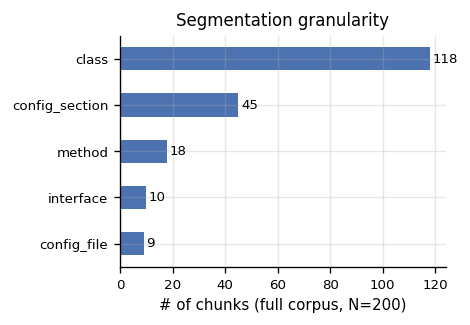

In [8]:
full_types = pd.Series([c["chunk_type"] for c in all_chunks]).value_counts()
N_FULL = len(all_chunks)
for t, n in full_types.items():
    claim(f"corpus.full_type.{t}", int(n))
    claim(f"corpus.full_pct.{t}", 100 * n / N_FULL)
claim("corpus.n_full", N_FULL)
claim("corpus.n_java", sum(1 for c in all_chunks if c["chunk_type"] in ("class", "method", "interface")))
claim("corpus.n_config", sum(1 for c in all_chunks if c["chunk_type"] in ("config_section", "config_file")))

gran_df = pd.DataFrame({"chunks": full_types, "share_%": (100 * full_types / N_FULL).round(1)})
display(gran_df)

fig, ax = plt.subplots(figsize=(IEEE_COL, 2.5))
full_types.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel(f"# of chunks (full corpus, N={N_FULL})")
ax.set_title("Segmentation granularity")
for i, v in enumerate(full_types.sort_values()):
    ax.text(v + 1, i, str(v), va="center", fontsize=8)
savefig(fig, "01_chunk_granularity"); plt.show()

**Figure 1.** Chunk type distribution over the full corpus (N = 200). Class-level chunks dominate
(118, 59%) over method-level chunks (18, 9%), and the rest are interfaces (10) and configuration (54
chunks, which are excluded both from the retrieval corpus and from the structural analysis in
[Section 9.1](#sec9-1)). The segmentation
actually applied is therefore **mostly class-level**: in a Spring Boot codebase most controllers,
services and repositories are cohesive enough that the strategy does not split them into methods.

<a id="sec2-3"></a>
### 2.3 Which Fragments Enter the Retrieval Corpus, and Why

The retrieval corpus is a subset of the repository's Java chunks, chosen on purpose instead of
sampled at random. That decision shapes the absolute scores, so the selection is described here in
full.

Two inclusion criteria were applied:

1. **Service coverage.** Every functional microservice (gateway, user service, fund transfer,
   utility payment, core banking) and both infrastructure modules (service registry, config server)
   must be represented.
2. **Component-type coverage.** REST controllers, services at class and method level, JPA
   repositories, entities, DTOs, mappers, security filters, global exception handlers, Feign and REST
   clients, enums and unit tests must all be represented.

Two exclusions:

3. **Configuration chunks** (`application.yml`, `Dockerfile` and similar) stay out of retrieval,
   because the queries are conceptual and none of them targets a configuration value. They are also
   left out of the embedding-space analysis in [Section 9.1](#sec9-1), because they have no
   comparable package or service structure, so that analysis uses all 146 Java fragments rather than
   the 94 of the retrieval corpus. This is why the two sections work with different fragment counts,
   and the cell below prints both.
4. **Near-duplicates and boilerplate** with no distinct retrieval target were dropped.

**Distractors** are defined by outcome rather than by intention: a corpus fragment that appears in no
query's relevance set. Under that definition the count is exact, and it is computed below.

In [9]:
# the repository's Java fragments, used again in 9.1 and 10.1
JAVA_IDX   = [i for i, c in enumerate(all_chunks) if c["chunk_type"] in ("class", "method", "interface")]
JAVA       = [all_chunks[i] for i in JAVA_IDX]
JAVA_TEXTS = [c["content"] for c in JAVA]

def cmeta(c, key): return c["metadata"].get(key)

def comp_type(c):
    return cmeta(c, "spring_type") or c["chunk_type"]

audit = pd.DataFrame({
    "service":   [chunk_service(c) for c in JAVA],
    "component": [comp_type(c)     for c in JAVA],
    "selected":  [i in set(CORPUS_ORIG) for i in JAVA_IDX],
})

by_service = (audit.groupby("service")["selected"].agg(java_chunks="size", selected="sum")
              .assign(coverage_pct=lambda d: (100 * d.selected / d.java_chunks).round(0)))
by_component = (audit.groupby("component")["selected"].agg(java_chunks="size", selected="sum")
                .sort_values("java_chunks", ascending=False))

# distractors: in the corpus, never relevant to any query
relevant_positions = set().union(*[set(g) for g in GT])
distractors = sorted(set(range(len(CORPUS_CHUNKS))) - relevant_positions)

claim("corpus.n_eval", len(CORPUS_TEXTS))
claim("corpus.n_distractors", len(distractors))
claim("corpus.n_ever_relevant", len(relevant_positions))
claim("corpus.n_services_covered", int((by_service.selected > 0).sum()))
claim("corpus.n_services_total", len(by_service))
claim("corpus.n_component_types_covered", int((by_component.selected > 0).sum()))
claim("corpus.n_component_types_total", len(by_component))
claim("corpus.selection_rate_pct", 100 * len(CORPUS_TEXTS) / len(JAVA))

display(by_service)
display(by_component)

,java_chunks,selected,coverage_pct
service,,,
core-banking-service,52,38,73.0
internet-banking-api-gateway,4,3,75.0
internet-banking-config-server,2,1,50.0
internet-banking-fund-transfer-service,26,14,54.0
internet-banking-service-registry,2,1,50.0
internet-banking-user-service,36,24,67.0
internet-banking-utility-payment-service,24,13,54.0


,java_chunks,selected
component,,
class,86,51
service,13,10
interface,10,4
method,10,10
config,8,8
entity,7,1
controller,6,4
controller_advice,4,4
component,2,2


**94 of the 146 Java chunks** (64%) form the retrieval corpus. Coverage is complete on both
criteria: **7 of 7** modules and **9 of 9** component types contribute at least one fragment.

Of the 94 fragments, 76 are relevant to at least one query and **18 are never relevant**. Those are
the distractors, and the count is exact under the definition above.

This design has a cost: the corpus over-represents fragments that some query can reach, so the
absolute scores are optimistic compared with retrieval over the whole repository. [Section
10](#sec10) runs the whole comparison again on all 146 Java chunks, to see whether the
*conclusions*, as opposed to the absolute numbers, depend on this choice.

<a id="sec2-4"></a>
### 2.4 Query Taxonomy

The 37 queries are grouped into four categories. The taxonomy is the independent variable tested in
[Section 8](#sec8). The four categories were defined first, and each query was written for one
of them.

| Category | Definition | Example | Expected mechanism |
| --- | --- | --- | --- |
| **T1 - Location** | Names the target artifact explicitly, a class or a service. | *"Which class configures the routing rules of the API Gateway?"* | Lexical matching should be competitive, since the query shares identifiers with the target. |
| **T2 - Behavior** | Describes a flow or a piece of business logic without naming classes. | *"How is a fund transfer between two accounts executed end to end?"* | Dense retrieval should be necessary, since there is little direct vocabulary overlap. |
| **T3 - Cross-cutting** | The answer spans several microservices (error handling, security, inter-service communication). | *"How is global exception handling implemented across all microservices?"* | Hard for every method, since no single fragment holds the whole answer. |
| **T4 - Tests** | Looks for the unit tests covering a behavior. | *"What tests check the insufficient-funds scenario?"* | Dense retrieval should help, since test method names carry only weak lexical cues. |

The last column holds the predictions of **H2**, and [Section 8](#sec8) reports where they held and
where they did not.

One caveat about the queries themselves: they were written **after** the corpus was fixed
(*chunks-first*), which guarantees a ground truth for every query at the cost of circularity and of
the realistic case of a query with no answer. [Section 11](#sec11) states what it
prevents.

<a id="sec2-5"></a>
### 2.5 What the Benchmark Can and Cannot Reward

Two properties of the relevance sets constrain every metric reported later, and both follow from the
annotation rather than from any retrieval method. They come from the same arithmetic. However good a
ranker is, the number of relevant fragments it can place in the top *k* is at most
**`min(|rel|, k)`**: it cannot retrieve relevant fragments that do not exist, and it cannot fit more
than *k* of them into *k* slots. That bound is the numerator of both cut-off metrics, and the two
divide it by different denominators:

* **Precision@5** divides by the cut-off, so `P@5 ≤ min(|rel|,5)/5`. A query with **fewer** than 5
  relevant fragments therefore cannot reach 1.0. With `|rel| = 2` a perfect ranking still scores
  2/5 = 0.40, because the three remaining slots can only be filled with fragments that are
  irrelevant by definition. The shortfall is a property of the annotation, not a retrieval error.
* **Recall@5** divides by the size of the relevance set, so `R@5 ≤ min(|rel|,5)/|rel|`. A query with
  **more** than 5 relevant fragments cannot reach 1.0 either. With `|rel| = 7` only 5 of the 7 fit
  inside the window, so a perfect ranking scores 5/7 = 0.71 and the two it had to leave out are
  counted as misses.

The two ceilings bind in opposite directions, so no single cut-off escapes both: *k* = 5 is too wide
for the small relevance sets and too narrow for the large ones, and both cases occur in this
benchmark. The size of each relevance set therefore has to be known before any score is interpreted.
The cell below computes the distribution of sizes, the per-category counts and the exact attainable
ceiling of each cut-off metric. [Section 5](#sec5) then defines the metrics against those ceilings and
adds **R-precision**, which escapes the problem by construction rather than by correction: its cut-off
is `|rel|` itself, so the numerator and the denominator move together and the attainable maximum is
1.0 for every query.

**Annotation.** Relevance was assigned by a **single annotator** with knowledge of the repository
structure; agreement was not measured, so no agreement statistic is reported and none is implied
([Section 11](#sec11)).

In [10]:
K = 5
qrows = []
for i, q in enumerate(QUERIES):
    n_gt = len(GT[i])
    qrows.append({
        "query": q["id"], "category": catlabel(q["category"]), "n_relevant": n_gt,
        "P@5_max":  min(n_gt, K) / K,          # cannot exceed |rel|/5 when |rel| < 5
        "R@5_max":  min(n_gt, K) / n_gt,       # cannot exceed 5/|rel| when |rel| > 5
        "R@10_max": min(n_gt, 10) / n_gt,
        "text": q["text"],
    })
queries_df = pd.DataFrame(qrows)

cat_stats = (queries_df.groupby("category")
             .agg(n_queries=("query", "size"), mean_relevant=("n_relevant", "mean"),
                  min_relevant=("n_relevant", "min"), max_relevant=("n_relevant", "max"),
                  mean_P5_max=("P@5_max", "mean"), mean_R5_max=("R@5_max", "mean"))
             .round(3))
gt_dist = queries_df["n_relevant"].value_counts().sort_index().rename("queries").to_frame()
gt_dist.index.name = "|relevant|"

n_over_5  = int((queries_df.n_relevant > K).sum())
n_under_5 = int((queries_df.n_relevant < K).sum())

claim("bench.n_queries", len(QUERIES))
claim("bench.mean_relevant", queries_df.n_relevant.mean())
claim("bench.min_relevant", int(queries_df.n_relevant.min()))
claim("bench.max_relevant", int(queries_df.n_relevant.max()))
claim("bench.n_queries_gt5", n_over_5)
claim("bench.n_queries_lt5", n_under_5)
claim("bench.mean_P5_ceiling", queries_df["P@5_max"].mean())
claim("bench.mean_R5_ceiling", queries_df["R@5_max"].mean())
claim("bench.mean_R10_ceiling", queries_df["R@10_max"].mean())
claim("bench.min_R5_ceiling", queries_df["R@5_max"].min())
for c in CATS:
    r = cat_stats.loc[catlabel(c)]
    claim(f"bench.n_queries.{c}", int(r.n_queries))
    claim(f"bench.mean_relevant.{c}", float(r.mean_relevant))

display(cat_stats)
display(gt_dist.T)

display(queries_df[["query", "category", "n_relevant", "P@5_max", "R@5_max", "text"]].head(12))

,n_queries,mean_relevant,min_relevant,max_relevant,mean_P5_max,mean_R5_max
category,,,,,,
T1 - Location,10,1.400,1,4,0.280,1.000
T2 - Behavior,9,3.444,2,5,0.689,1.000
T3 - Cross-cutting,9,4.333,3,6,0.822,0.963
T4 - Tests,9,3.000,1,7,0.533,0.950


|relevant|,1,2,3,4,5,6,7
queries,11,3,9,8,2,3,1


,query,category,n_relevant,P@5_max,R@5_max,text
0,Q01,T1 - Location,1,0.2,1.0,Which class configures the routing rules of th...
1,Q02,T1 - Location,1,0.2,1.0,Where is JWT security configured for the API G...
2,Q03,T1 - Location,2,0.4,1.0,What class performs Keycloak user operations i...
3,Q04,T1 - Location,1,0.2,1.0,Which repository persists fund transfer records?
4,Q05,T1 - Location,1,0.2,1.0,What JPA entity maps bank accounts to the data...
5,Q06,T1 - Location,1,0.2,1.0,Which controller exposes the utility payment R...
6,Q07,T1 - Location,1,0.2,1.0,What class decodes Feign client errors in the ...
7,Q08,T1 - Location,4,0.8,1.0,Where is the InsufficientFundsException class ...
8,Q09,T1 - Location,1,0.2,1.0,Which class maps a UserEntity to the User doma...
9,Q10,T1 - Location,1,0.2,1.0,What interface is the Feign client toward core...


Across 37 queries a relevance set holds 1 to 7 fragments, mean 3.00. The two ceilings both bite:

* **31 queries have fewer than 5 relevant fragments**, so the mean attainable Precision@5 over the
  benchmark is 0.573, not 1.0. Precision@5 is consequently *not* used as a primary metric, and a
  ceiling-normalised variant (`nP@5`) is reported alongside it.
* **4 queries have more than 5 relevant fragments**, so Recall@5 cannot reach 1.0 for them either:
  the worst case is 0.714 and the mean attainable Recall@5 is 0.979. [Section 5](#sec5) therefore
  also reports Recall@10, whose mean attainable value on this benchmark is 1.000.

Relevance-set size also **varies with category**, since T1 queries name one artifact while T3
queries span several services, so category and query difficulty are linked by construction. Any
category effect has to be read against the `mean_relevant` column above, and [Section 8](#sec8)
tests the confound directly.

<a id="sec3"></a>
## 3. Retrieval Configurations

Twelve configurations from three families are compared.

<a id="sec3-1"></a>
### 3.1 Dense: Seven Embedding Models

| Config | Origin | Dim | Max input | Role in the comparison |
| --- | --- | --- | --- | --- |
| `all-MiniLM-L6-v2` | open weights | 384 | 256 | Fast, lightweight, the usual first choice. |
| `all-mpnet-base-v2` | open weights | 768 | 384 | Strongest general-purpose *sentence-transformers* model. |
| `paraphrase-MiniLM-L3-v2` | open weights | 384 | 128 | **Control**: optimised for paraphrase similarity, not for retrieval. |
| `unixcoder-base` | open weights | 768 | 1024 | **Code-specific pre-trained encoder** (Guo et al., ACL 2022). |
| `jina-code-embeddings-0.5b` | open weights | 896 | 32768 | **Code-specific retriever**, trained contrastively with task instructions. |
| `gemini-embedding-001` · `RETRIEVAL_QUERY` | managed API | 768 | 2048 | General-purpose retrieval task type. |
| `gemini-embedding-001` · `CODE_RETRIEVAL_QUERY` | managed API | 768 | 2048 | Task type documented for natural-language-to-code retrieval. |

Three entries in that table need a word on why they are there.

**The control.** `paraphrase-MiniLM-L3-v2` was trained for paraphrase similarity rather than for
retrieval. It shows what happens when the training objective does not match the task, which gives the
other results a floor to be compared against. Its input window is only 128 tokens, and
[Section 6](#sec6) measures how much of that result comes from the window rather than from the
objective.

**Two kinds of "code-specific" model.** The two are not interchangeable. `unixcoder-base` is a code
**encoder**: pre-trained on code with a multi-modal objective and widely used as a code
representation backbone, but not fine-tuned contrastively to rank code fragments against
natural-language questions. `jina-code-embeddings-0.5b` is a code **retriever**: trained with
instruction prefixes for specific retrieval directions, and `nl2code`, from a natural-language query
to a code fragment, is exactly the direction used here. Including only one of them would mix
"trained on code" with "trained to retrieve code", and [Section 7](#sec7) shows that the difference
matters.

**Gemini task types.** The `task_type` argument is not a hint added at query time. The Gemini
Embedding technical report (Lee et al., *Gemini Embedding: Generalizable Embeddings from Gemini*,
arXiv:2503.07891) describes task prescriptions as part of the training objective, and documents
`CODE_RETRIEVAL_QUERY` for retrieval from a natural-language query to code. The model version, the
access date, and the fact that the 768 dimensions come from reducing the model's output
dimensionality through `output_dimensionality` rather than being its native width, are all recorded
in [Section 1.2](#sec1-2). Document fragments are always embedded with `RETRIEVAL_DOCUMENT`, so the
two variants differ **only in how the query is embedded**. No claim is made about the relative cost of
the two task types.

Under **H1**, since the corpus is Java, the code-specific task type and the code-specific models
should rank above the general-purpose ones. [Section 7](#sec7) reports where that held.

<a id="sec3-2"></a>
### 3.2 Lexical: BM25 (Okapi)

BM25 is the standard IR baseline, and on this corpus it is a strong one: several queries name a class
or a service outright, where term matching has a real advantage over a semantic model. Reporting
dense results without it would leave the gains unattributed.

**Code-aware tokenisation.** An identifier such as `FundTransferController` has to match *fund*,
*transfer* and *controller* in a query. The pipeline:

1. splits `camelCase`, `snake_case` and dotted identifiers (`FundTransferController` → `fund transfer controller`);
2. lowercases and removes stopwords, that is Java keywords plus English function words, among them
   *how*, *does*, *what* and *system*, which appear in almost every query and would otherwise
   dominate the IDF weighting;
3. applies Snowball stemming, so that *exceptions* matches *exception* and *globally* matches
   *global*.

Default parameters (k1 = 1.5, b = 0.75), **not tuned**.

<a id="sec3-3"></a>
### 3.3 Hybrid: Dense Plus Lexical Fusion

Four fusions are reported. Each pairing answers a different question:

| Config | Fusion | Dense side | Question it answers |
| --- | --- | --- | --- |
| `hybrid-rrf` | RRF, k = 60 | Gemini `RETRIEVAL_QUERY` | Does fusion improve on the managed-API deployment? |
| `hybrid-wsum` | weighted sum, α = 0.5 | Gemini `RETRIEVAL_QUERY` | Does the fusion method matter, with the inputs held fixed? |
| `hybrid-rrf-mpnet` | RRF, k = 60 | `all-mpnet-base-v2` | The same question for a **fully local** deployment, where no fragment leaves the premises. |
| `hybrid-rrf-code` | RRF, k = 60 | `jina-code-embeddings-0.5b` | Does lexical fusion still add anything once the dense side is code-specialised? |

* **RRF** *(Reciprocal Rank Fusion)* gives each fragment `Σ_r 1/(k + rank_r(d))`. It uses only rank
  order and never raw magnitudes, which is what makes it applicable here, since BM25 scores and
  cosine similarities are not on a comparable scale.
* **Weighted sum** averages min-max-normalised scores inside each query:
  `α·dense_norm + (1−α)·bm25_norm`, with α = 0.5.

**Neither fusion was tuned on this benchmark.** There is no train/test split, so tuning would
invalidate every number that follows. `k = 60` is the value from the original RRF paper (Cormack,
Clarke and Büttcher, SIGIR 2009), established on TREC collections of hundreds of thousands of
documents. A 94-fragment corpus is four orders of magnitude smaller, and at that scale `k = 60` may
flatten the rank differences that fusion depends on. [Section 10.2](#sec10-2) therefore sweeps `k` and
reports the result as a sensitivity check rather than as a tuned choice.

In [11]:
# ---- the twelve configurations ----------------------------------------------
DENSE_CONFIGS = {
    "all-MiniLM-L6-v2":          {"type": "st"},
    "all-mpnet-base-v2":         {"type": "st"},
    "paraphrase-MiniLM-L3-v2":   {"type": "st"},
    "unixcoder-base":            {"type": "hf",  "hf_id": "microsoft/unixcoder-base", "max_len": 1024},
    "jina-code-0.5b":            {"type": "st",  "hf_id": "jinaai/jina-code-embeddings-0.5b",
                                  "trust_remote_code": True,
                                  "prompt_query": "nl2code_query", "prompt_doc": "nl2code_document"},
    "gemini-retrieval":          {"type": "gemini", "task": "RETRIEVAL_QUERY"},
    "gemini-code":               {"type": "gemini", "task": "CODE_RETRIEVAL_QUERY"},
}
# fusion pairings: (dense config, fusion method) - see 3.3
HYBRID_CONFIGS = {
    "hybrid-rrf":       {"dense": "gemini-retrieval", "method": "rrf",  "k": 60},
    "hybrid-wsum":      {"dense": "gemini-retrieval", "method": "wsum", "alpha": 0.5},
    "hybrid-rrf-mpnet": {"dense": "all-mpnet-base-v2", "method": "rrf", "k": 60},
    "hybrid-rrf-code":  {"dense": "jina-code-0.5b",    "method": "rrf", "k": 60},
}

JAVA_SW = {"public","private","protected","static","final","void","return","class","interface",
    "enum","extends","implements","import","package","new","this","super","null","true","false",
    "if","else","for","while","throw","throws","try","catch","finally","int","long","double",
    "float","boolean","string","override","annotation"}
EN_SW = {"the","a","an","and","or","of","to","in","is","are","how","does","do","what","which",
    "this","that","these","those","with","for","on","by","as","at","from","it","its","be","work","system"}
STOPWORDS = JAVA_SW | EN_SW
_STEMMER = snowballstemmer.stemmer("english")

def code_tokenize(text: str) -> List[str]:
    text = re.sub(r"([a-z0-9])([A-Z])", r"\1 \2", text)   # camelCase -> camel Case
    text = re.sub(r"[_\-.]", " ", text)                    # snake_case, kebab-case, dots
    toks = [t for t in re.findall(r"[A-Za-z]{2,}", text.lower()) if t not in STOPWORDS]
    return [s for s in _STEMMER.stemWords(toks) if s not in STOPWORDS]

claim("config.n_total", len(DENSE_CONFIGS) + 1 + len(HYBRID_CONFIGS))
claim("config.n_dense", len(DENSE_CONFIGS))
claim("config.n_hybrid", len(HYBRID_CONFIGS))

print("Code-aware tokenization example:")
print("  'How is a fund transfer executed?' ->", code_tokenize("How is a fund transfer executed?"))
print("  'FundTransferController.java'      ->", code_tokenize("FundTransferController.java")[:6])
print(f"\n{len(DENSE_CONFIGS)} dense + 1 lexical + {len(HYBRID_CONFIGS)} hybrid = "
      f"{len(DENSE_CONFIGS) + 1 + len(HYBRID_CONFIGS)} configurations")

Code-aware tokenization example:
  'How is a fund transfer executed?' -> ['fund', 'transfer', 'execut']
  'FundTransferController.java'      -> ['fund', 'transfer', 'control', 'java']

7 dense + 1 lexical + 4 hybrid = 12 configurations


<a id="sec4"></a>
## 4. Embeddings and the Score Matrix

<a id="sec4-1"></a>
### 4.1 Generating the Embeddings

Corpus and query embeddings are computed once per model and cached to `cache/*.npy`. A second run
reads the cache instead of regenerating, which makes every number below deterministic and keeps the
managed-API call count at zero on repeat runs. Cache keys include the corpus size, so changing the
corpus invalidates them instead of silently reusing old vectors.

Three embedding interfaces are involved. The *sentence-transformers* models expose pooling directly.
`unixcoder-base` ships no pooling configuration, since it is an encoder rather than a sentence model,
so its embeddings are taken from the last hidden state with attention-masked **mean pooling**,
L2-normalised. `jina-code-embeddings-0.5b` needs the instruction prefix pair for the
retrieval direction, and receives `nl2code_query` for queries and `nl2code_document` for fragments.

For Gemini, fragments are embedded **once** with `RETRIEVAL_DOCUMENT` and shared by both query
variants, which differ only in the query-side task type. That is one API call per variant.

In [12]:
TAG = f"c{len(CORPUS_TEXTS)}"
PRECOMPUTED, MODEL_INFO = {}, {}

def embed_st(model, texts, prompt_name=None):
    kw = {"show_progress_bar": False}
    if prompt_name: kw["prompt_name"] = prompt_name
    return np.asarray(model.encode(list(texts), **kw))

def embed_meanpool(hf_id, texts, max_len, bs=8):
    """Attention-masked mean pooling over the last hidden state, L2-normalised."""
    import torch
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(hf_id); mdl = AutoModel.from_pretrained(hf_id).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), bs):
            b = tok(list(texts[i:i+bs]), padding=True, truncation=True,
                    max_length=max_len, return_tensors="pt")
            h = mdl(**b).last_hidden_state
            m = b["attention_mask"].unsqueeze(-1).float()
            v = (h * m).sum(1) / m.sum(1)
            out.append(torch.nn.functional.normalize(v, dim=-1).cpu().numpy())
    return np.vstack(out)

def embed_gemini(client, texts, task, bs=60):
    out = []
    for i in range(0, len(texts), bs):
        r = client.models.embed_content(
            model=GEMINI_MODEL, contents=list(texts[i:i+bs]),
            config=types.EmbedContentConfig(task_type=task, output_dimensionality=GEMINI_DIM))
        out.extend(e.values for e in r.embeddings)
    return np.array(out)

# ---- local models ------------------------------------------------------------
for name, cfg in DENSE_CONFIGS.items():
    hf_id = cfg.get("hf_id", name if "/" in name else f"sentence-transformers/{name}")
    if cfg["type"] == "st":
        st = SentenceTransformer(hf_id, trust_remote_code=cfg.get("trust_remote_code", False))
        PRECOMPUTED[name] = {
            "corpus":  cached(f"{TAG}__{name}__corpus",
                              lambda st=st, c=cfg: embed_st(st, CORPUS_TEXTS, c.get("prompt_doc"))),
            "queries": cached(f"v3q__{name}",
                              lambda st=st, c=cfg: embed_st(st, QUERY_TEXTS, c.get("prompt_query")))}
        MODEL_INFO[name] = {"hf_id": hf_id, "revision": hf_revision(hf_id),
                            "max_input": int(st.max_seq_length), "tokenizer": st.tokenizer}
    elif cfg["type"] == "hf":
        from transformers import AutoTokenizer
        ml = cfg["max_len"]
        PRECOMPUTED[name] = {
            "corpus":  cached(f"{TAG}__{name}__corpus", lambda h=hf_id, m=ml: embed_meanpool(h, CORPUS_TEXTS, m)),
            "queries": cached(f"v3q__{name}",          lambda h=hf_id, m=ml: embed_meanpool(h, QUERY_TEXTS, m))}
        MODEL_INFO[name] = {"hf_id": hf_id, "revision": hf_revision(hf_id),
                            "max_input": ml, "tokenizer": AutoTokenizer.from_pretrained(hf_id)}

# ---- managed API -------------------------------------------------------------
_client = genai.Client(api_key=GOOGLE_API_KEY)
gem_corpus = cached(f"{TAG}__gemini_RETRIEVAL_DOCUMENT",
                    lambda: embed_gemini(_client, CORPUS_TEXTS, "RETRIEVAL_DOCUMENT"))
for name, cfg in DENSE_CONFIGS.items():
    if cfg["type"] != "gemini": continue
    q = cached(f"v3q__gemini_{cfg['task']}", lambda cfg=cfg: embed_gemini(_client, QUERY_TEXTS, cfg["task"]))
    PRECOMPUTED[name] = {"corpus": gem_corpus, "queries": q}
    MODEL_INFO[name] = {"hf_id": GEMINI_MODEL, "revision": PROVENANCE["managed_api"]["access_date"],
                        "max_input": 2048, "tokenizer": None}   # documented limit; no local tokenizer

emb_df = pd.DataFrame([{"config": n, "model": MODEL_INFO[n]["hf_id"],
                        "revision": str(MODEL_INFO[n]["revision"])[:12],
                        "dim": PRECOMPUTED[n]["corpus"].shape[1],
                        "max_input_tokens": MODEL_INFO[n]["max_input"]}
                       for n in DENSE_CONFIGS])
PROVENANCE["models"] = emb_df.to_dict("records")
emb_df

,config,model,revision,dim,max_input_tokens
0,all-MiniLM-L6-v2,sentence-transformers/all-MiniLM-L6-v2,1110a243fdf4,384,256
1,all-mpnet-base-v2,sentence-transformers/all-mpnet-base-v2,12e86a3c702f,768,384
2,paraphrase-MiniLM-L3-v2,sentence-transformers/paraphrase-MiniLM-L3-v2,4ca70771034a,384,128
3,unixcoder-base,microsoft/unixcoder-base,5604afdc964f,768,1024
4,jina-code-0.5b,jinaai/jina-code-embeddings-0.5b,4db235132daf,896,32768
5,gemini-retrieval,gemini-embedding-001,2026-10-10,768,2048
6,gemini-code,gemini-embedding-001,2026-10-10,768,2048


<a id="sec4-2"></a>
### 4.2 Unified Score Matrix

Every configuration is reduced to one matrix of shape `(queries × fragments)`: cosine similarity for
the dense configurations, Okapi BM25 scores for the lexical one, and fused scores for the hybrids.
All metrics, tests and figures downstream read only these matrices, so no configuration gets special
treatment anywhere in the evaluation.

In [13]:
bm25 = BM25Okapi([code_tokenize(t) for t in CORPUS_TEXTS])
BM25_SCORES = np.vstack([bm25.get_scores(code_tokenize(q)) for q in QUERY_TEXTS])

def dense_scores(name):
    e = PRECOMPUTED[name]
    return cosine_similarity(e["queries"], e["corpus"])

def minmax_rows(M):
    lo, hi = M.min(1, keepdims=True), M.max(1, keepdims=True)
    return (M - lo) / np.where(hi - lo == 0, 1.0, hi - lo)

def rrf_fuse(mats, k=60):
    f = np.zeros_like(mats[0], float)
    for M in mats:
        order = np.argsort(-M, 1); ranks = np.empty_like(order)
        for r in range(M.shape[0]): ranks[r, order[r]] = np.arange(1, M.shape[1] + 1)
        f += 1.0 / (k + ranks)
    return f

def wsum_fuse(dense, lexical, alpha=0.5):
    return alpha * minmax_rows(dense) + (1 - alpha) * minmax_rows(lexical)

SCORES = {n: dense_scores(n) for n in DENSE_CONFIGS}
SCORES["bm25"] = BM25_SCORES
for h, cfg in HYBRID_CONFIGS.items():
    d = SCORES[cfg["dense"]]
    SCORES[h] = (rrf_fuse([d, BM25_SCORES], k=cfg["k"]) if cfg["method"] == "rrf"
                 else wsum_fuse(d, BM25_SCORES, cfg["alpha"]))

CONFIGS    = list(SCORES)
DENSE_ONLY = list(DENSE_CONFIGS)
HYBRIDS    = list(HYBRID_CONFIGS)
FAMILY = {**{n: "dense" for n in DENSE_ONLY}, "bm25": "lexical", **{n: "hybrid" for n in HYBRIDS}}

assert all(SCORES[n].shape == (len(QUERIES), len(CORPUS_TEXTS)) for n in CONFIGS)
print(f"{len(CONFIGS)} score matrices of shape {SCORES[CONFIGS[0]].shape}:")
for fam in ("dense", "lexical", "hybrid"):
    print(f"  {fam:8s} {[DISPLAY.get(n, n) for n in CONFIGS if FAMILY[n] == fam]}")

12 score matrices of shape (37, 94):
  dense    ['MiniLM-L6', 'MPNet', 'Paraphrase-L3', 'UniXcoder', 'JinaCode', 'Gemini-RETR', 'Gemini-CODE']
  lexical  ['BM25']
  hybrid   ['RRF(Gem+BM25)', 'WSum(Gem+BM25)', 'RRF(MPNet+BM25)', 'RRF(Jina+BM25)']


<a id="sec5"></a>
## 5. Metrics

Every metric is computed **per query** and then averaged over queries, so the unit of analysis is
always the query and every paired test below works on 37 paired observations. Relevance is binary
throughout: the annotation records whether a fragment answers the query, not how well it answers it.

[Section 2.5](#sec2-5) showed that two of these metrics have query-dependent ceilings, so the
definitions below state each ceiling instead of assuming 1.0.

| Metric | Definition | Attainable maximum |
| --- | --- | --- |
| **Precision@5** | fraction of the top-5 that is relevant | `min(\|rel\|,5)/5`, below 1.0 whenever a query has fewer than 5 relevant fragments |
| **nP@5** | Precision@5 divided by that ceiling | 1.0 by construction |
| **Recall@5** | fraction of the relevant set found in the top-5 | `min(\|rel\|,5)/\|rel\|`, **below 1.0 whenever a query has more than 5 relevant fragments** |
| **Recall@10** | the same at cut-off 10 | `min(\|rel\|,10)/\|rel\|`, 1.0 for every query in this benchmark |
| **R-precision** | precision at rank `\|rel\|`, so the cut-off adapts to each query | 1.0 for every query, with no normalisation needed |
| **MRR** | reciprocal rank of the **first** relevant fragment | 1.0 |
| **nDCG@5** | log-discounted gain over the top-5, normalised by the ideal ranking | 1.0 |

Two of them deserve a note.

**R-precision** answers the objection that any fixed cut-off is arbitrary when relevance sets range
from 1 to 7 fragments. It sets the cut-off to `|rel|` for each query, so it is comparable across
queries and categories without a correction term. It is reported next to nDCG@5, not instead of it.

**MRR** is the metric closest to how retrieved context is actually consumed: a generation stage
receives the top-*k* fragments, and the rank of the first correct fragment conditions what the model
can ground its answer on.

**nDCG@5 is the primary summary metric**, because it is the only one that responds both to how many
relevant fragments were found and to where they were placed. Where a conclusion depends on the choice
of metric, that dependence is reported instead of being resolved by picking the favourable metric.

**Uncertainty.** Confidence intervals are **95% percentile bootstrap** intervals over the 37
per-query scores (`N_BOOT` resamples, seed `SEED`, both pinned in [1.2](#sec1-2)), and the query,
not the query-fragment pair, is the resampling unit. Paired comparisons use the **Wilcoxon
signed-rank test** on per-query differences. With N = 37 and ties present, the two-sided *p*-value
has a floor: no result can be more significant than that floor, however consistent the difference is.
[Section 7](#sec7) therefore prints the smallest attainable *p* next to each observed *p*.

In [14]:
def ranking(s): return np.argsort(-s).tolist()

def precision_at_k(r, rel, k): return len(set(r[:k]) & set(rel)) / k
def recall_at_k(r, rel, k):    return len(set(r[:k]) & set(rel)) / len(rel) if rel else 0.0

def r_precision(r, rel):
    """Precision at rank |rel|: the cut-off adapts to the query, so the ceiling is always 1.0."""
    n = len(rel)
    return len(set(r[:n]) & set(rel)) / n if n else 0.0

def reciprocal_rank(r, rel):
    for i, x in enumerate(r, 1):
        if x in rel: return 1.0 / i
    return 0.0

def ndcg_at_k(r, rel, k):
    dcg  = sum(1/np.log2(i+1) for i, x in enumerate(r[:k], 1) if x in rel)
    idcg = sum(1/np.log2(i+1) for i in range(1, min(len(rel), k)+1))
    return dcg/idcg if idcg else 0.0

# metrics reported in the summary tables, in the order they appear
METRICS     = ["P@5", "nP@5", "R@5", "R@10", "R-Prec", "nDCG@5", "RR"]
PRIMARY     = "nDCG@5"
CI_METRICS  = ["R@5", "R-Prec", "nDCG@5", "RR"]

def per_query_metrics(S, gt=None):
    """Per-query metrics of score matrix `S` against relevance sets `gt` (default: GT)."""
    gt = GT if gt is None else gt
    out = []
    for i, rel in enumerate(gt):
        r = ranking(S[i])
        p5_ceiling = min(len(rel), 5) / 5
        row = {"query": QUERY_IDS[i], "cat": QUERY_CAT[i]}
        for k in (1, 3, 5, 10):
            row[f"P@{k}"] = precision_at_k(r, rel, k)
            row[f"R@{k}"] = recall_at_k(r, rel, k)
        row["nP@5"]   = row["P@5"] / p5_ceiling if p5_ceiling else 0.0
        row["R-Prec"] = r_precision(r, rel)
        row["RR"]     = reciprocal_rank(r, rel)
        row["nDCG@5"] = ndcg_at_k(r, rel, 5)
        out.append(row)
    return pd.DataFrame(out).set_index("query")

PQ = {n: per_query_metrics(SCORES[n]) for n in CONFIGS}

# ---- uncertainty and paired testing ----------------------------------------
def bootstrap_ci(v, n=None, a=0.05):
    """95% percentile bootstrap over per-query scores; the query is the resampling unit."""
    n = N_BOOT if n is None else n
    v = np.asarray(v, float)
    m = RNG.choice(v, size=(n, len(v)), replace=True).mean(1)
    return v.mean(), np.percentile(m, 100*a/2), np.percentile(m, 100*(1-a/2))

def min_attainable_p(n_nonzero):
    """Smallest two-sided p the Wilcoxon signed-rank test can return with this many non-tied pairs."""
    if n_nonzero < 1: return np.nan
    return min(1.0, 2.0 ** (1 - n_nonzero))     # all differences of one sign, exact test

def wilcoxon_pair(a, b, metric, pq=None):
    """Paired Wilcoxon on per-query differences; returns mean delta, p, and the p floor."""
    pq = PQ if pq is None else pq
    x, y = pq[a][metric].values, pq[b][metric].values
    d = x - y
    n_eff = int(np.sum(d != 0))
    p_min = min_attainable_p(n_eff)
    if n_eff == 0:
        return 0.0, np.nan, p_min, n_eff
    try:
        _, p = stats.wilcoxon(x, y)
        return float(d.mean()), float(p), p_min, n_eff
    except ValueError:
        return float(d.mean()), np.nan, p_min, n_eff

def holm(pvals):
    """Holm-Bonferroni adjusted p-values, order preserved."""
    p = np.asarray(pvals, float)
    ok = ~np.isnan(p)
    adj = np.full_like(p, np.nan)
    idx = np.argsort(p[ok]); m = ok.sum()
    running, out = 0.0, np.empty(m)
    for rank, j in enumerate(idx):
        running = max(running, (m - rank) * p[ok][j])
        out[j] = min(1.0, running)
    adj[ok] = out
    return adj

claim("metrics.n_queries", len(QUERIES))
claim("metrics.n_boot", N_BOOT)
claim("metrics.primary", PRIMARY)
print(f"metrics defined - unit of analysis: query (N={len(QUERIES)}) - primary metric: {PRIMARY}")
print(f"bootstrap: {N_BOOT:,} resamples, percentile method, seed {SEED}")

metrics defined - unit of analysis: query (N=37) - primary metric: nDCG@5
bootstrap: 10,000 resamples, percentile method, seed 42


<a id="sec6"></a>
## 6. Control: Is the Model Comparison Confounded by Input Budget?

The models in [3.1](#sec3-1) do not all accept the same amount of input. Three of them have windows
narrower than the longest fragments in the corpus, so part of those fragments never reaches the
encoder. If the narrow-window models are also the lowest-scoring ones, the ranking in
[Section 7](#sec7) could be measuring **how much text a model was allowed to see** rather than how
well it represents code, and any conclusion about training objectives would rest on that.

The question is measurable, so it is measured here in two steps.

1. **Measure the exposure.** For each model, tokenise every fragment with *that model's own*
   tokenizer, then report how many fragments exceed its window and what fraction of their content
   survives. Token counts are not comparable across tokenizers, which is why each model is measured
   with its own.
2. **Price the budget.** Take a model whose window is wide enough to truncate nothing
   (`jina-code-0.5b`), re-embed the corpus after truncating it artificially to each of the narrow
   budgets, and measure the resulting loss in retrieval quality. This holds the model fixed and
   varies only the input budget, which is the comparison the confound calls for.

If step 2 shows a cost comparable to the spread between models, then the model comparison is
confounded. If the cost is much smaller than that spread, the confound is present but does not
account for the ranking.

In [15]:
# ---- step 1: exposure per model, each with its own tokenizer -----------------
exp_rows = []
for name in DENSE_CONFIGS:
    info = MODEL_INFO[name]; tk, lim = info["tokenizer"], info["max_input"]
    if tk is None:
        exp_rows.append({"config": name, "max_input": lim, "max_chunk_tokens": np.nan,
                         "truncated": np.nan, "truncated_%": np.nan, "content_kept_%": np.nan})
        continue
    n = np.array([len(tk.encode(t, add_special_tokens=True, truncation=False)) for t in CORPUS_TEXTS])
    exp_rows.append({"config": name, "max_input": lim, "max_chunk_tokens": int(n.max()),
                     "truncated": int((n > lim).sum()),
                     "truncated_%": round(100 * float((n > lim).mean()), 1),
                     "content_kept_%": round(100 * float(np.mean(np.minimum(n, lim) / n)), 1)})
trunc_df = pd.DataFrame(exp_rows).set_index("config")
display(trunc_df)
for name, r in trunc_df.iterrows():
    if not np.isnan(r["truncated_%"]):
        claim(f"trunc.pct.{name}", float(r["truncated_%"]))
        claim(f"trunc.kept.{name}", float(r["content_kept_%"]))
        claim(f"trunc.limit.{name}", int(r["max_input"]))

# ---- step 2: price the budget, model held fixed ------------------------------
BUDGET_REF = "jina-code-0.5b"
BUDGETS = [128, 256, 384, None]

def ndcg5_of(S):
    return float(np.mean([ndcg_at_k(np.argsort(-S[i]).tolist(), GT[i], 5) for i in range(len(GT))]))

_ref_cfg = DENSE_CONFIGS[BUDGET_REF]
_ref = SentenceTransformer(_ref_cfg["hf_id"], trust_remote_code=True)
_rtok = _ref.tokenizer
_qv = PRECOMPUTED[BUDGET_REF]["queries"]

budget_rows = []
for b in BUDGETS:
    if b is None:
        cv, tp = PRECOMPUTED[BUDGET_REF]["corpus"], 0.0
    else:
        ids = [_rtok.encode(t, add_special_tokens=False, truncation=False) for t in CORPUS_TEXTS]
        tp = 100 * float(np.mean([len(i) > b for i in ids]))
        cv = cached(f"{TAG}__{BUDGET_REF}__trunc{b}",
                    lambda ids=ids, b=b: embed_st(_ref, [_rtok.decode(i[:b]) for i in ids],
                                                 _ref_cfg["prompt_doc"]))
    budget_rows.append({"budget_tokens": "full" if b is None else b,
                        "fragments_truncated_%": round(tp, 1),
                        "nDCG@5": round(ndcg5_of(cosine_similarity(_qv, cv)), 4)})
budget_df = pd.DataFrame(budget_rows)
full_score = budget_df.loc[budget_df.budget_tokens == "full", "nDCG@5"].iloc[0]
budget_df["cost_vs_full"] = (budget_df["nDCG@5"] - full_score).round(4)
display(budget_df)

worst = budget_df.iloc[budget_df["nDCG@5"].idxmin()]
claim("trunc.ref_model", BUDGET_REF)
claim("trunc.full_score", float(full_score))
claim("trunc.tightest_budget", int(budget_df.budget_tokens.iloc[0]))
claim("trunc.tightest_score", float(worst["nDCG@5"]))
claim("trunc.max_cost", float(abs(worst["cost_vs_full"])))

,max_input,max_chunk_tokens,truncated,truncated_%,content_kept_%
config,,,,,
all-MiniLM-L6-v2,256,847.0,36.0,38.3,86.8
all-mpnet-base-v2,384,847.0,21.0,22.3,94.8
paraphrase-MiniLM-L3-v2,128,847.0,68.0,72.3,63.6
unixcoder-base,1024,628.0,0.0,0.0,100.0
jina-code-0.5b,32768,510.0,0.0,0.0,100.0
gemini-retrieval,2048,NaN,NaN,NaN,NaN
gemini-code,2048,NaN,NaN,NaN,NaN


,budget_tokens,fragments_truncated_%,nDCG@5,cost_vs_full
0,128,57.4,0.8593,-0.0194
1,256,21.3,0.8742,-0.0045
2,384,4.3,0.8787,0.0000
3,full,0.0,0.8787,0.0000


0.0194

**Exposure.** The narrow-window models are affected unevenly, and heavily in one case.
`paraphrase-MiniLM-L3-v2` truncates **72.3%** of the fragments at its 128-token window, retaining
only 63.6% of their content on average; `all-MiniLM-L6-v2` truncates 38.3% and `all-mpnet-base-v2`
22.3%. Both code-specific models truncate **nothing** (0% and 0%), so their scores cannot be a
window effect. The confound is real, it is unevenly distributed, and it points in the same direction
as the expected result, which is the least convenient case for interpretation.

**Price.** With `jina-code-0.5b` held fixed and given less input, nDCG@5 falls from 0.8787 at the
full window to 0.8593 at 128 tokens, a cost of **0.019** at the budget where more than half the
fragments lose content.

Input budget therefore costs something, and the amount is small. [Section 7](#sec7) compares the
spread between models with this figure, and any model that is both narrow-windowed and low-scoring
has to be read with this number in mind instead of having its whole gap attributed to the training
objective.

<a id="sec7"></a>
## 7. Sub-question 1: How Much Does the Choice of Embedding Model Matter?

The question asks for a magnitude rather than for a yes or no, since both answers are informative.
If model choice is secondary, the retrieval-oriented configurations should sit inside a narrow band
with overlapping confidence intervals and the omnibus test should not reject; if it is decisive, one
configuration should separate from the rest on the primary metric, keep that separation on the other
metrics, and survive a paired test against the runner-up after correction.

Three quantities are reported for each comparison, because any one of them alone is misleading at this
sample size: the **effect** (mean paired difference), the **uncertainty** (bootstrap interval), and
the **smallest *p* the test could return** given N = 37 and the observed ties. A *p*-value of 0.03
means something different when the floor is 10⁻⁵ than when the floor is 0.02.

In [16]:
summary = pd.DataFrame({DISPLAY[n]: PQ[n][METRICS].mean() for n in CONFIGS}).T.round(4)
summary["family"] = [FAMILY[n] for n in CONFIGS]

best_per_metric = {m: summary[m].idxmax() for m in METRICS}
for m in METRICS:
    claim(f"sq1.best.{m}", best_per_metric[m])
    claim(f"sq1.best_value.{m}", float(summary[m].max()))

BEST = summary[PRIMARY].idxmax()                      # display name
BEST_KEY = next(n for n in CONFIGS if DISPLAY[n] == BEST)
RUNNER   = summary.drop(index=BEST)[PRIMARY].idxmax()
RUNNER_KEY = next(n for n in CONFIGS if DISPLAY[n] == RUNNER)
n_metrics_won = sum(1 for m in METRICS if best_per_metric[m] == BEST)

claim("sq1.best_config", BEST)
claim("sq1.runner_config", RUNNER)
claim("sq1.n_metrics", len(METRICS))
claim("sq1.n_metrics_won_by_best", n_metrics_won)

display(summary)
print(f"\nbest per metric: " + ", ".join(f"{m}={best_per_metric[m]}" for m in METRICS))

,P@5,nP@5,R@5,R@10,R-Prec,nDCG@5,RR,family
MiniLM-L6,0.3459,0.6811,0.6689,0.7910,0.6113,0.6700,0.7830,dense
MPNet,0.4000,0.7676,0.7553,0.8730,0.6550,0.7464,0.8498,dense
Paraphrase-L3,0.2973,0.6000,0.5869,0.6946,0.4669,0.5453,0.6238,dense
UniXcoder,0.3351,0.5973,0.5824,0.7878,0.4167,0.5526,0.6794,dense
JinaCode,0.4757,0.8698,0.8513,0.9450,0.8095,0.8787,0.9730,dense
Gemini-RETR,0.4486,0.8495,0.8346,0.9374,0.7140,0.8258,0.9153,dense
Gemini-CODE,0.4432,0.8189,0.8031,0.9419,0.7320,0.8228,0.9505,dense
BM25,0.3622,0.6973,0.6833,0.8149,0.5288,0.6467,0.7179,lexical
RRF(Gem+BM25),0.4595,0.8545,0.8378,0.9185,0.6946,0.8159,0.9018,hybrid
WSum(Gem+BM25),0.4378,0.8279,0.8130,0.9140,0.6608,0.7651,0.8153,hybrid



best per metric: P@5=JinaCode, nP@5=JinaCode, R@5=JinaCode, R@10=JinaCode, R-Prec=JinaCode, nDCG@5=JinaCode, RR=JinaCode


In [17]:
# ---- bootstrap intervals over per-query scores -------------------------------
ci_rows = []
for n in CONFIGS:
    for met in CI_METRICS:
        m, lo, hi = bootstrap_ci(PQ[n][met].values)
        ci_rows.append({"config": DISPLAY[n], "family": FAMILY[n], "metric": met,
                        "mean": round(m, 4), "ci_lo": round(lo, 4), "ci_hi": round(hi, 4)})
ci_df = pd.DataFrame(ci_rows)
CI = {(r.config, r.metric): (r.mean, r.ci_lo, r.ci_hi) for r in ci_df.itertuples()}

for n in CONFIGS:
    m, lo, hi = CI[(DISPLAY[n], PRIMARY)]
    claim(f"sq1.mean.{n}", m); claim(f"sq1.lo.{n}", lo); claim(f"sq1.hi.{n}", hi)

display(ci_df[ci_df.metric == PRIMARY].set_index("config").drop(columns="metric"))

,family,mean,ci_lo,ci_hi
config,,,,
MiniLM-L6,dense,0.6700,0.5489,0.7842
MPNet,dense,0.7464,0.6510,0.8344
Paraphrase-L3,dense,0.5453,0.4170,0.6705
UniXcoder,dense,0.5526,0.4320,0.6662
JinaCode,dense,0.8787,0.8193,0.9327
Gemini-RETR,dense,0.8258,0.7457,0.8973
Gemini-CODE,dense,0.8228,0.7444,0.8944
BM25,lexical,0.6467,0.5233,0.7647
RRF(Gem+BM25),hybrid,0.8159,0.7397,0.8871


In [18]:
# ---- omnibus tests: which configurations each one covers is stated explicitly -
GENERAL_DENSE = ["all-MiniLM-L6-v2", "all-mpnet-base-v2"]
CONTROL       = ["paraphrase-MiniLM-L3-v2"]
RETRIEVAL_DENSE = [n for n in DENSE_ONLY if n not in CONTROL]

omni_groups = {
    "all 12 configurations":            CONFIGS,
    "7 dense models":                   DENSE_ONLY,
    "6 dense minus the paraphrase control": RETRIEVAL_DENSE,
    "4 general-purpose dense models": GENERAL_DENSE + ["gemini-retrieval", "gemini-code"],
}
omni_rows = []
for label, grp in omni_groups.items():
    chi2, p = stats.friedmanchisquare(*[PQ[n][PRIMARY].values for n in grp])
    spread = max(PQ[n][PRIMARY].mean() for n in grp) - min(PQ[n][PRIMARY].mean() for n in grp)
    omni_rows.append({"group": label, "k": len(grp), "chi2": round(chi2, 3),
                      "p": p, "nDCG@5 spread": round(spread, 3),
                      "members": ", ".join(DISPLAY[n] for n in grp)})
omni_df = pd.DataFrame(omni_rows)
display(omni_df.drop(columns="members").assign(p=lambda d: d.p.map("{:.2e}".format)))

for r in omni_df.itertuples():
    key = "all12" if r.k == 12 else ("dense7" if r.k == 7 else ("retr6" if r.k == 6 else "v2set"))
    claim(f"sq1.omni_p.{key}", float(r.p)); claim(f"sq1.omni_chi2.{key}", float(r.chi2))
    claim(f"sq1.omni_spread.{key}", float(getattr(r, '_5')))
print("\nmembers of each omnibus group:")
for r in omni_df.itertuples(): print(f"  {r.group}: {r.members}")

,group,k,chi2,p,nDCG@5 spread
0,all 12 configurations,12,66.329,6.06e-10,0.333
1,7 dense models,7,44.077,7.14e-08,0.333
2,6 dense minus the paraphrase control,6,33.740,2.68e-06,0.326
3,4 general-purpose dense models,4,5.250,1.54e-01,0.156



members of each omnibus group:
  all 12 configurations: MiniLM-L6, MPNet, Paraphrase-L3, UniXcoder, JinaCode, Gemini-RETR, Gemini-CODE, BM25, RRF(Gem+BM25), WSum(Gem+BM25), RRF(MPNet+BM25), RRF(Jina+BM25)
  7 dense models: MiniLM-L6, MPNet, Paraphrase-L3, UniXcoder, JinaCode, Gemini-RETR, Gemini-CODE
  6 dense minus the paraphrase control: MiniLM-L6, MPNet, UniXcoder, JinaCode, Gemini-RETR, Gemini-CODE
  4 general-purpose dense models: MiniLM-L6, MPNet, Gemini-RETR, Gemini-CODE


In [19]:
# ---- pairwise, Holm-corrected, with the p floor ------------------------------
pairs = [
    ("jina-code-0.5b", "gemini-retrieval"),          # code-specific retriever vs managed API
                                                     # (also the best-vs-runner-up pair)
    ("jina-code-0.5b", "unixcoder-base"),            # retriever vs encoder, both code-specific
    ("gemini-retrieval", "gemini-code"),             # does the code task type help?
    ("gemini-retrieval", "all-mpnet-base-v2"),       # managed API vs best general open weights
    ("gemini-retrieval", "bm25"),                    # dense vs lexical
    ("hybrid-rrf", "gemini-retrieval"),              # does fusion help the API model?
    ("hybrid-rrf-code", "jina-code-0.5b"),           # does fusion help the code retriever?
    ("hybrid-rrf-mpnet", "all-mpnet-base-v2"),       # does fusion help the local model?
    ("all-mpnet-base-v2", "paraphrase-MiniLM-L3-v2"),# retrieval objective vs paraphrase objective
]
wx_rows = []
for a, b in pairs:
    for met in (PRIMARY, "R-Prec", "RR"):
        d, p, p_min, n_eff = wilcoxon_pair(a, b, met)
        wx_rows.append({"A": DISPLAY[a], "B": DISPLAY[b], "metric": met,
                        "delta": round(d, 4), "p": p, "p_min": p_min, "n_nonzero": n_eff})
wx_df = pd.DataFrame(wx_rows)
wx_df["p_holm"] = np.nan
for met, g in wx_df.groupby("metric"):
    wx_df.loc[g.index, "p_holm"] = holm(g["p"].values)
wx_df["sig_holm"] = wx_df.p_holm < 0.05

fmt = wx_df.assign(p=lambda d: d.p.map(lambda v: f"{v:.4f}" if pd.notna(v) else "n/a"),
                   p_holm=lambda d: d.p_holm.map(lambda v: f"{v:.4f}" if pd.notna(v) else "n/a"),
                   p_min=lambda d: d.p_min.map(lambda v: f"{v:.2e}" if pd.notna(v) else "n/a"))
display(fmt[fmt.metric == PRIMARY].drop(columns="metric").set_index(["A", "B"]))

_bv = wx_df[(wx_df.A == BEST) & (wx_df.B == RUNNER) & (wx_df.metric == PRIMARY)].iloc[0]
claim("sq1.best_vs_runner_delta", float(_bv.delta))
claim("sq1.best_vs_runner_p", float(_bv.p))
claim("sq1.best_vs_runner_p_holm", float(_bv.p_holm))
claim("sq1.best_vs_runner_pmin", float(_bv.p_min))
claim("sq1.n_sig_holm", int(wx_df[wx_df.metric == PRIMARY].sig_holm.sum()))
claim("sq1.n_sig_raw", int((wx_df[wx_df.metric == PRIMARY].p < 0.05).sum()))
claim("sq1.n_pairs", len(pairs))
for nm, (a, b) in {"jina_vs_gemini": ("JinaCode", "Gemini-RETR"),
                   "jina_vs_unix":   ("JinaCode", "UniXcoder"),
                   "gem_task":       ("Gemini-RETR", "Gemini-CODE"),
                   "fusion_code":    ("RRF(Jina+BM25)", "JinaCode"),
                   "fusion_api":     ("RRF(Gem+BM25)", "Gemini-RETR"),
                   "dense_vs_bm25":  ("Gemini-RETR", "BM25"),
                   "objective":      ("MPNet", "Paraphrase-L3")}.items():
    r = wx_df[(wx_df.A == a) & (wx_df.B == b) & (wx_df.metric == PRIMARY)].iloc[0]
    claim(f"sq1.{nm}.delta", float(r.delta)); claim(f"sq1.{nm}.p", float(r.p))
    claim(f"sq1.{nm}.p_holm", float(r.p_holm))

delta       p     p_min  n_nonzero  p_holm  \
A               B                                                            
JinaCode        Gemini-RETR    0.0529  0.2461  1.53e-05         17  0.9845   
                UniXcoder      0.3261  0.0000  5.96e-08         25  0.0003   
Gemini-RETR     Gemini-CODE    0.0030  0.7220  3.91e-03          9  1.0000   
                MPNet          0.0795  0.1060  9.54e-07         21  0.5301   
                BM25           0.1791  0.0204  1.49e-08         27  0.1224   
RRF(Gem+BM25)   Gemini-RETR   -0.0099  0.9870  4.77e-07         22  1.0000   
RRF(Jina+BM25)  JinaCode      -0.0574  0.0162  3.05e-05         16  0.1131   
RRF(MPNet+BM25) MPNet          0.0013  0.5712  7.63e-06         18  1.0000   
MPNet           Paraphrase-L3  0.2011  0.0029  5.96e-08         25  0.0236   

                               sig_holm  
A               B                        
JinaCode        Gemini-RETR       False  
                UniXcoder          True  
Gemini-RETR     Gemini-CODE       False  
                MPNet             False  
                BM25              False  
RRF(Gem+BM25)   Gemini-RETR       False  
RRF(Jina+BM25)  JinaCode          False  
RRF(MPNet+BM25) MPNet             False  
MPNet           Paraphrase-L3      True

  fig: 02_retrieval_metrics


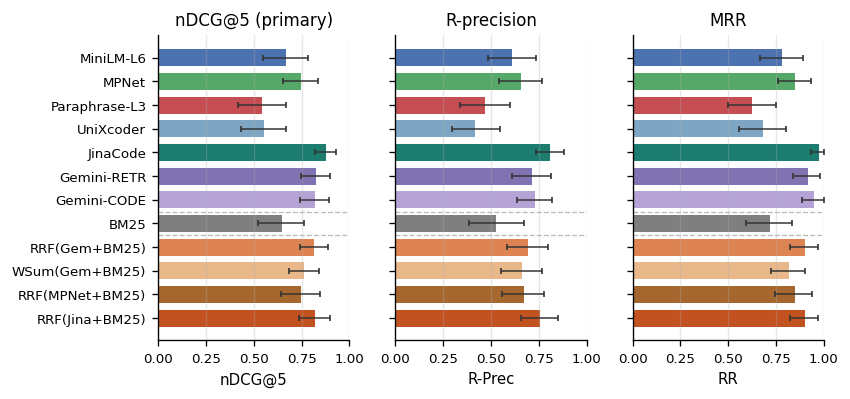

True

In [20]:
order = DENSE_ONLY + ["bm25"] + HYBRIDS
shown = [PRIMARY, "R-Prec", "RR"]
titles = {PRIMARY: "nDCG@5 (primary)", "R-Prec": "R-precision", "RR": "MRR"}

fig, axes = plt.subplots(1, 3, figsize=(IEEE_WIDE, 3.4), sharey=True)
ypos = np.arange(len(order))[::-1]
for ax, met in zip(axes, shown):
    means = [CI[(DISPLAY[n], met)][0] for n in order]
    los   = [CI[(DISPLAY[n], met)][0] - CI[(DISPLAY[n], met)][1] for n in order]
    his   = [CI[(DISPLAY[n], met)][2] - CI[(DISPLAY[n], met)][0] for n in order]
    ax.barh(ypos, means, xerr=[los, his], color=[color(n) for n in order],
            error_kw=dict(lw=0.9, capsize=2, ecolor="#333333"), height=0.72)
    ax.set_xlim(0, 1.0); ax.set_title(titles[met]); ax.set_xlabel(met)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos); axes[0].set_yticklabels([DISPLAY[n] for n in order])
for ax in axes:
    ax.axhline(ypos[len(DENSE_ONLY)] + 0.5, color="#bbbbbb", lw=0.8, ls="--")
    ax.axhline(ypos[len(DENSE_ONLY) + 1] + 0.5, color="#bbbbbb", lw=0.8, ls="--")
fig.tight_layout()
savefig(fig, "02_retrieval_metrics"); plt.show()

claim("sq1.gap_to_runner", CI[(BEST, PRIMARY)][0] - CI[(RUNNER, PRIMARY)][0])
_overlap = CI[(BEST, PRIMARY)][1] <= CI[(RUNNER, PRIMARY)][2]
claim("sq1.ci_overlap_best_runner", bool(_overlap))

**Figure 2.** nDCG@5, R-precision and MRR for the 12 configurations (mean with 95% bootstrap
confidence intervals over N = 37 queries, 10,000 resamples). Dashed lines separate the three
families: dense (top), lexical, fusion (bottom). **JinaCode** has the highest mean on 7 of the 7
metrics reported in the summary table, leading the runner-up Gemini-RETR by 0.053 nDCG@5, and the
two intervals still overlap. R-precision, which has no query-dependent ceiling, separates the
configurations more sharply than nDCG@5 does, and the ordering it produces is not identical, so
"best" here depends in part on the metric.

### Sub-question 1: What the Data Shows

**The field is wide.** The omnibus test across all 12 configurations rejects decisively (Friedman χ²
= 66.3, p = 6.06e-10), and so does the test over the 6 dense models with the paraphrase control
removed (χ² = 33.7, p = 2.68e-06). The spread across those six models is **0.326 nDCG@5**. Over only
the four general-purpose dense models the same test does **not** reject (p = 0.154, spread 0.156).
Whether retrieval-oriented models look interchangeable therefore depends on which models are in the
set: among general-purpose models they nearly are, and once a code-specialised retriever joins the
set they are not.

**The top of the field is not separable at this sample size.** JinaCode has the highest mean on **7
of 7** metrics, nDCG@5 = 0.879 (95% CI [0.819, 0.933]) against 0.826 for Gemini-RETR. The paired
difference is only +0.053, with p = 0.246 (not significant after Holm correction: 0.985), and the
confidence intervals overlap. With N = 37 queries, **no difference was detected between the two
leading configurations**, which describes the power of this benchmark rather than showing that the
two are equivalent. Agreement across all 7 metrics is suggestive, but it is not a significance test.

The answer to the sub-question is therefore neither "model choice is secondary" nor "one model
wins": **the penalty for choosing badly is large, while the reward for choosing between the top
candidates stays inside the noise of this benchmark.**

**Training on code and training to retrieve code are different things, and this is where the large
effects are.** Both code-specific models see every fragment in full (0% and 0% truncated), so
neither result can be a window effect, yet they land at opposite ends of the field, +0.326 nDCG@5
apart (p < 0.0001, Holm 0.0003, one of the comparisons that survives correction). `unixcoder-base`
is a pre-trained code *encoder* with no contrastive training for ranking code against
natural-language questions, and it performs close to the paraphrase control. Pre-training on code is
not what makes a code retriever; the retrieval objective is. The general-purpose side points the
same way: `all-mpnet-base-v2` beats the paraphrase control by +0.201 nDCG@5 (p = 0.0029, Holm
0.0236), the only other comparison that survives correction. Both surviving effects come from a
mismatch between the training objective and the task, and [Section 6](#sec6) already ruled out input
budget as their cause: the tightest budget costs 0.019 nDCG@5, an order of magnitude less than
either gap.

**The code-specific task type does not help.** Gemini `RETRIEVAL_QUERY` and `CODE_RETRIEVAL_QUERY`
differ by +0.003 nDCG@5 (p = 0.722). The H1 expectation stated in [3.1](#sec3-1), that a task type
documented for natural-language-to-code retrieval would win on a Java corpus, is **not supported**.
The two variants do reorder results, so they are not producing identical rankings, but the rankings
are of indistinguishable quality.

**Fusion does not help a strong dense side.** Adding BM25 to the API model changes nDCG@5 by -0.010
(p = 0.987), and adding it to the code retriever changes it by -0.057 (p = 0.016 uncorrected, 0.113
after Holm, so suggestive rather than established). The direction matches what rank fusion does: it
pulls a strong ranker towards a weaker one. Fusion is not a free improvement, and on this benchmark
it is no improvement at all for the best dense configuration.

**Dense against lexical.** Gemini `RETRIEVAL_QUERY` exceeds BM25 by +0.179 nDCG@5 (p = 0.020, Holm
0.122), an effect that does not survive correction. BM25 does not fall inside the range of the
retrieval-oriented dense models: it sits below all of them except `unixcoder-base` and the
paraphrase control. [Section 8](#sec8) shows that this aggregate comparison hides the more useful
result, because the standing of BM25 depends strongly on what is being asked.

**How to read the *p*-values.** 4 of the 9 comparisons on nDCG@5 reach p < 0.05 uncorrected and only
2 survive Holm correction, and both counts are shown so that the gap between them is visible. No
conclusion above rests on an uncorrected comparison.

<a id="sec8"></a>
## 8. Sub-question 2: Query Intent Against Model Choice

[Section 7](#sec7) compared configurations by averaging over all 37 queries. An average can hide a
reordering: a configuration that is best on half the queries and worst on the other half looks
mediocre. This section asks whether the **kind of question being asked** changes which configuration
should be used, and how that effect compares in size with the effect of the configuration itself.

The comparison is not straightforward, for three reasons.

* **The two factors are not of the same kind.** Configuration varies *within* a query, since every
  configuration is run on every query, while category varies *between* queries. A range computed over
  four categories of about nine queries each and a range computed over every configuration on every
  query do not have the same sampling properties, so a variance decomposition that treats them alike
  cannot be interpreted.
* **Category is linked to difficulty.** [Section 2.5](#sec2-5) showed that relevance-set size
  varies systematically by category, as the `mean_relevant` column of the table below repeats, so a
  category effect might be a relevance-set-size effect under another name.
* **A third outcome is possible.** If different configurations win in different categories, the right
  description is an **interaction**, and then neither main effect describes the data, whichever of the
  two is larger.

Three analyses address those three problems in turn:

1. A **mixed-effects model** with query as a random intercept, which puts the within-query factor
   (configuration) and the between-query factor (category) on a common scale, and which can be
   extended with relevance-set size to test the confound directly.
2. **Permutation tests** in which each factor is permuted the way its own design allows, that is
   category labels shuffled *across* queries and configuration labels shuffled *within* each query,
   so that each observed effect is compared with a null built from its own structure.
3. An explicit **interaction test** together with a per-category ranking of the configurations, so
   that an interaction can be reported directly instead of being inferred from two main effects.

In [21]:
cat_tab = pd.DataFrame({DISPLAY[n]: PQ[n].groupby("cat")[PRIMARY].mean() for n in CONFIGS}).T[CATS]
cat_tab.columns = [catlabel(c) for c in CATS]
cat_tab = cat_tab.round(3)

cat_means = cat_tab.mean(axis=0).sort_values(ascending=False)          # difficulty ranking of categories
cfg_range = (cat_tab.max(axis=1) - cat_tab.min(axis=1))                     # how much one config moves across categories
cat_spread = (cat_tab.max(axis=0) - cat_tab.min(axis=0))                    # how much configs differ inside a category

display(cat_tab)
display(pd.DataFrame({"category mean nDCG@5": cat_means.round(3),
                      "n queries": [claim(f'sq2.n.{c}', CLAIMS[f'bench.n_queries.{c}']["value"])
                                    for c in sorted(CATS, key=lambda c: -cat_means[catlabel(c)])],
                      "mean |relevant|": [CLAIMS[f'bench.mean_relevant.{c}']["value"]
                                          for c in sorted(CATS, key=lambda c: -cat_means[catlabel(c)])],
                      "spread across configs": cat_spread.reindex(cat_means.index).round(3)}))

for i, (lab, v) in enumerate(cat_means.items(), 1):
    claim(f"sq2.cat_mean.{lab}", float(v)); claim(f"sq2.cat_rank.{lab}", i)
claim("sq2.easiest_cat", cat_means.index[0])
claim("sq2.hardest_cat", cat_means.index[-1])
claim("sq2.cat_range", float(cat_means.max() - cat_means.min()))
claim("sq2.max_cfg_range", float(cfg_range.max()))
claim("sq2.max_cfg_range_config", cfg_range.idxmax())
claim("sq2.min_cfg_range", float(cfg_range.min()))
claim("sq2.min_cfg_range_config", cfg_range.idxmin())
claim("sq2.max_cat_spread", float(cat_spread.max()))
claim("sq2.max_cat_spread_cat", cat_spread.idxmax())
claim("sq2.min_cat_spread", float(cat_spread.min()))
print("category difficulty ranking:", " > ".join(cat_means.index))

,T1 - Location,T2 - Behavior,T3 - Cross-cutting,T4 - Tests
MiniLM-L6,0.839,0.411,0.748,0.663
MPNet,0.857,0.581,0.762,0.774
Paraphrase-L3,0.841,0.357,0.613,0.337
UniXcoder,0.520,0.536,0.642,0.515
JinaCode,0.948,0.684,0.927,0.949
Gemini-RETR,0.844,0.738,0.744,0.975
Gemini-CODE,0.794,0.698,0.838,0.963
BM25,0.752,0.400,0.718,0.704
RRF(Gem+BM25),0.841,0.675,0.825,0.920
WSum(Gem+BM25),0.820,0.605,0.778,0.851


,category mean nDCG@5,n queries,mean |relevant|,spread across configs
T1 - Location,0.814,10,1.400,0.428
T4 - Tests,0.782,9,3.000,0.638
T3 - Cross-cutting,0.772,9,4.333,0.314
T2 - Behavior,0.570,9,3.444,0.381


category difficulty ranking: T1 - Location > T4 - Tests > T3 - Cross-cutting > T2 - Behavior


In [22]:
# ---- long format: one row per (query, configuration) -------------------------
import statsmodels.formula.api as smf

long_rows = []
for n in CONFIGS:
    d = PQ[n]
    for q, cat, v in zip(d.index, d["cat"], d[PRIMARY]):
        long_rows.append({"query": q, "config": n, "category": cat, "y": float(v),
                          "nrel": len(GT[QUERY_IDS.index(q)])})
LONG = pd.DataFrame(long_rows)
# categorical dtype, so the formulas below need no C() term
LONG["config"]   = pd.Categorical(LONG["config"],   categories=CONFIGS)
LONG["category"] = pd.Categorical(LONG["category"], categories=CATS)
claim("sq2.n_observations", len(LONG))

def _fit(formula):
    return smf.mixedlm(formula, LONG, groups=LONG["query"]).fit(reml=False)

def lrt(full, reduced, df):
    """Likelihood-ratio test between two nested mixed models fitted by ML."""
    chi2 = 2 * (full.llf - reduced.llf)
    return float(chi2), float(stats.chi2.sf(chi2, df)), df

M_null = _fit("y ~ 1")
M_cfg  = _fit("y ~ config")
M_cat  = _fit("y ~ category")
M_main = _fit("y ~ config + category")
M_rel  = _fit("y ~ config + nrel")
M_all  = _fit("y ~ config + category + nrel")
M_int  = _fit("y ~ config * category")

k_cfg, k_cat = len(CONFIGS) - 1, len(CATS) - 1
lr_rows = [
    ("configuration | category",            *lrt(M_main, M_cat,  k_cfg)),
    ("category | configuration",            *lrt(M_main, M_cfg,  k_cat)),
    ("relevance-set size | configuration",  *lrt(M_rel,  M_cfg,  1)),
    ("category | configuration + |rel|",    *lrt(M_all,  M_rel,  k_cat)),
    ("|rel| | configuration + category",    *lrt(M_all,  M_main, 1)),
    ("configuration x category interaction",*lrt(M_int,  M_main, k_cfg * k_cat)),
]
lr_df = pd.DataFrame(lr_rows, columns=["effect", "chi2", "p", "df"])[["effect", "df", "chi2", "p"]]
display(lr_df.assign(chi2=lambda d: d.chi2.round(2), p=lambda d: d.p.map("{:.3e}".format)))

for name, key in [("configuration | category", "cfg"), ("category | configuration", "cat"),
                  ("relevance-set size | configuration", "rel"),
                  ("category | configuration + |rel|", "cat_adj"),
                  ("configuration x category interaction", "interaction")]:
    r = lr_df[lr_df.effect == name].iloc[0]
    claim(f"sq2.lrt_chi2.{key}", float(r.chi2)); claim(f"sq2.lrt_p.{key}", float(r.p))
    claim(f"sq2.lrt_df.{key}", int(r.df))

# variance the two factors account for, each on its own side of the design
vq_n, vr_n = float(M_null.cov_re.iloc[0, 0]), float(M_null.scale)
vq_m, vr_m = float(M_main.cov_re.iloc[0, 0]), float(M_main.scale)
claim("sq2.var_between_query_by_category", 100 * (1 - vq_m / vq_n))
claim("sq2.var_within_query_by_config",    100 * (1 - vr_m / vr_n))
print(f"\nbetween-query variance accounted for by category: {100*(1-vq_m/vq_n):.1f}%")
print(f"within-query variance accounted for by configuration: {100*(1-vr_m/vr_n):.1f}%")

,effect,df,chi2,p
0,configuration | category,11,92.17,6.264e-15
1,category | configuration,3,8.71,3.339e-02
2,relevance-set size | configuration,1,2.64,1.039e-01
3,category | configuration + |rel|,3,7.88,4.855e-02
4,|rel| | configuration + category,1,1.81,1.780e-01
5,configuration x category interaction,33,55.92,7.616e-03



between-query variance accounted for by category: 21.1%
within-query variance accounted for by configuration: 20.3%


In [23]:
# ---- permutation tests: each factor permuted as its own design allows --------
NPERM = 20_000
M = np.vstack([PQ[n][PRIMARY].values for n in CONFIGS])        # (configs x queries)
cats_arr = np.array(QUERY_CAT)
prng = np.random.default_rng(SEED)

def category_range(labels):
    """Range of category means, each averaged over all configurations."""
    return float(np.ptp([M[:, labels == c].mean() for c in CATS]))

def config_range(mat):
    """Range of configuration means, each averaged over all queries."""
    return float(np.ptp(mat.mean(1)))

obs_cat, obs_cfg = category_range(cats_arr), config_range(M)

null_cat = np.array([category_range(prng.permutation(cats_arr)) for _ in range(NPERM)])
null_cfg = np.empty(NPERM)
for i in range(NPERM):                                         # shuffle configs *within* each query
    idx = prng.permuted(np.tile(np.arange(M.shape[0])[:, None], M.shape[1]), axis=0)
    null_cfg[i] = config_range(np.take_along_axis(M, idx, axis=0))

perm_df = pd.DataFrame([
    {"factor": "category (between queries)", "observed range": round(obs_cat, 4),
     "null mean": round(null_cat.mean(), 4), "null sd": round(null_cat.std(), 4),
     "z": round((obs_cat - null_cat.mean()) / null_cat.std(), 2),
     "p": (null_cat >= obs_cat).mean()},
    {"factor": "configuration (within query)", "observed range": round(obs_cfg, 4),
     "null mean": round(null_cfg.mean(), 4), "null sd": round(null_cfg.std(), 4),
     "z": round((obs_cfg - null_cfg.mean()) / null_cfg.std(), 2),
     "p": (null_cfg >= obs_cfg).mean()},
])
display(perm_df.assign(p=lambda d: d.p.map(lambda v: f"<{1/NPERM:.0e}" if v == 0 else f"{v:.4f}")))

claim("sq2.perm_n", NPERM)
claim("sq2.perm_cat_obs", obs_cat); claim("sq2.perm_cat_z", float((obs_cat-null_cat.mean())/null_cat.std()))
claim("sq2.perm_cat_p", float((null_cat >= obs_cat).mean()))
claim("sq2.perm_cfg_obs", obs_cfg); claim("sq2.perm_cfg_z", float((obs_cfg-null_cfg.mean())/null_cfg.std()))
claim("sq2.perm_cfg_p", float((null_cfg >= obs_cfg).mean()))

,factor,observed range,null mean,null sd,z,p
0,category (between queries),0.2441,0.1442,0.0592,1.69,0.0580
1,configuration (within query),0.3334,0.1310,0.0311,6.52,<5e-05


0.0

  fig: 03_category_by_config


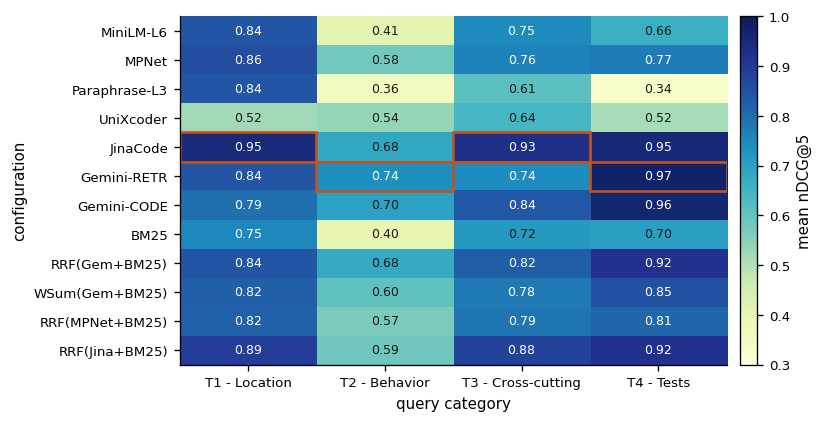

In [24]:
fig, ax = plt.subplots(figsize=(IEEE_WIDE, 3.6))
Mv = cat_tab.values
VMIN, VMAX = float(np.floor(Mv.min()*20)/20), 1.0
im = ax.imshow(Mv, cmap="YlGnBu", vmin=VMIN, vmax=VMAX, aspect="auto")
ax.set_xticks(range(len(cat_tab.columns))); ax.set_xticklabels(cat_tab.columns)
ax.set_yticks(range(len(cat_tab.index)));   ax.set_yticklabels(cat_tab.index)
ax.grid(False)
switch = VMIN + 0.62 * (VMAX - VMIN)
for i in range(Mv.shape[0]):
    for j in range(Mv.shape[1]):
        ax.text(j, i, f"{Mv[i,j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if Mv[i, j] > switch else "#1a1a1a")
for i, lab in enumerate(cat_tab.index):                       # ring the winner of each column
    for j in range(Mv.shape[1]):
        if Mv[i, j] == Mv[:, j].max():
            ax.add_patch(plt.Rectangle((j-0.5, i-0.5), 1, 1, fill=False, ec="#C2521F", lw=1.6))
ax.set_xlabel("query category"); ax.set_ylabel("configuration")
fig.colorbar(im, ax=ax, label="mean nDCG@5", pad=0.02)
fig.tight_layout(); savefig(fig, "03_category_by_config"); plt.show()

**Figure 3.** Mean nDCG@5 by configuration (rows) and query category (columns); the best
configuration in each column is outlined. **No configuration wins every category.** T4 - Tests shows
the widest spread across configurations (0.638) and the narrowest is 0.314; across categories, the
configuration that moves most is Paraphrase-L3 (0.504) and the steadiest is UniXcoder (0.127).
Variation across rows is therefore **not** uniformly smaller than variation across columns. The two
are comparable, which is what an interaction looks like rather than one dominant factor.

  fig: 04_interaction


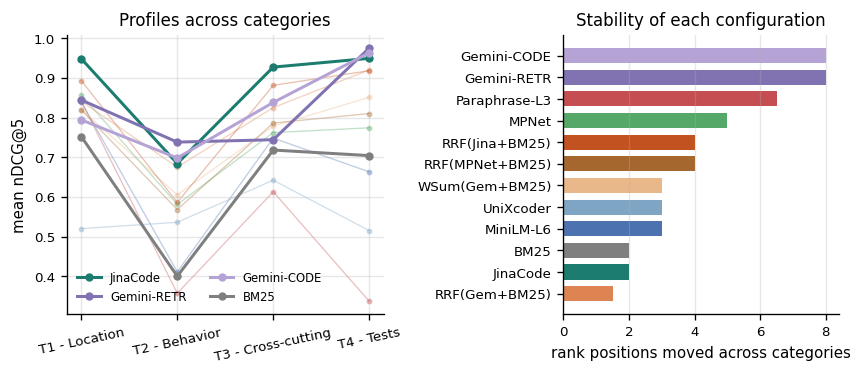

In [25]:
# ---- the interaction, drawn: where do configurations cross? ------------------
fig, axes = plt.subplots(1, 2, figsize=(IEEE_WIDE, 3.2), gridspec_kw={"width_ratios": [1.15, 1]})
xs = np.arange(len(CATS))
highlight = ["jina-code-0.5b", "gemini-retrieval", "gemini-code", "bm25"]

ax = axes[0]
for n in CONFIGS:
    v = cat_tab.loc[DISPLAY[n]].values
    hot = n in highlight
    ax.plot(xs, v, marker="o", ms=4 if hot else 2.5, lw=1.8 if hot else 0.8,
            color=color(n), alpha=1.0 if hot else 0.35,
            label=DISPLAY[n] if hot else None, zorder=3 if hot else 1)
ax.set_xticks(xs); ax.set_xticklabels([catlabel(c) for c in CATS], rotation=12)
ax.set_ylabel("mean nDCG@5"); ax.set_title("Profiles across categories")
ax.legend(loc="lower left", ncol=2, fontsize=7)

ax = axes[1]
ranks = cat_tab.rank(ascending=False, axis=0)
rng_rank = (ranks.max(axis=1) - ranks.min(axis=1)).sort_values()
ax.barh(np.arange(len(rng_rank)), rng_rank.values,
        color=[color(next(n for n in CONFIGS if DISPLAY[n] == d)) for d in rng_rank.index], height=0.7)
ax.set_yticks(np.arange(len(rng_rank))); ax.set_yticklabels(rng_rank.index)
ax.set_xlabel("rank positions moved across categories")
ax.set_title("Stability of each configuration"); ax.grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "04_interaction"); plt.show()

for d, v in rng_rank.items():
    claim(f"sq2.rank_range.{d}", float(v))
claim("sq2.most_stable", rng_rank.index[0]);  claim("sq2.most_stable_v", float(rng_rank.iloc[0]))
claim("sq2.least_stable", rng_rank.index[-1]); claim("sq2.least_stable_v", float(rng_rank.iloc[-1]))
for c in CATS:
    col = cat_tab[catlabel(c)]
    claim(f"sq2.winner.{c}", col.idxmax()); claim(f"sq2.winner_v.{c}", float(col.max()))

**Figure 4.** Left: nDCG@5 profile of every configuration across the four categories, with four of
them highlighted. Crossing lines show the interaction directly, since the ordering of configurations
is not preserved from one category to the next. Right: how many rank positions each configuration
moves between its best and worst category. **RRF(Gem+BM25)** moves 1.5 positions and **Gemini-CODE**
moves 8.0, so robustness to query type is itself a property that separates configurations, and an
aggregate table cannot show it.

In [26]:
# ---- does BM25 close the gap where lexical cues exist? ----------------------
DENSE_REF = "jina-code-0.5b"          # the leading dense configuration, fixed by section 7
cat_wx = []
for c in CATS:
    idx = [i for i in range(len(QUERIES)) if QUERY_CAT[i] == c]
    for met in (PRIMARY, "R-Prec"):
        x = PQ[DENSE_REF][met].values[idx]; y = PQ["bm25"][met].values[idx]
        d = x - y; n_eff = int((d != 0).sum())
        try:   p = float(stats.wilcoxon(x, y)[1]) if n_eff else np.nan
        except ValueError: p = np.nan
        cat_wx.append({"category": catlabel(c), "n": len(idx), "metric": met,
                       "dense": round(x.mean(), 3), "bm25": round(y.mean(), 3),
                       "delta": round(d.mean(), 3), "p": p,
                       "p_min": min_attainable_p(n_eff), "n_nonzero": n_eff})
cat_wx_df = pd.DataFrame(cat_wx)
cat_wx_df["p_holm"] = np.nan
for met, gg in cat_wx_df.groupby("metric"):
    cat_wx_df.loc[gg.index, "p_holm"] = holm(gg["p"].values)

display(cat_wx_df[cat_wx_df.metric == PRIMARY].drop(columns="metric").assign(
    p=lambda d: d.p.map(lambda v: f"{v:.4f}" if pd.notna(v) else "n/a"),
    p_holm=lambda d: d.p_holm.map(lambda v: f"{v:.4f}" if pd.notna(v) else "n/a"),
    p_min=lambda d: d.p_min.map("{:.2e}".format)).set_index("category"))

claim("sq2.dense_ref", DISPLAY[DENSE_REF])
for r in cat_wx_df[cat_wx_df.metric == PRIMARY].itertuples():
    key = r.category.split(" ")[0]
    claim(f"sq2.bm25_delta.{key}", float(r.delta)); claim(f"sq2.bm25_p.{key}", float(r.p))
    claim(f"sq2.bm25_p_holm.{key}", float(r.p_holm))
claim("sq2.bm25_n_sig", int((cat_wx_df[cat_wx_df.metric == PRIMARY].p_holm < 0.05).sum()))

,n,dense,bm25,delta,p,p_min,n_nonzero,p_holm
category,,,,,,,,
T1 - Location,10,0.948,0.752,0.196,0.1250,6.25e-02,5,0.2500
T2 - Behavior,9,0.684,0.400,0.284,0.0625,3.12e-02,6,0.1875
T3 - Cross-cutting,9,0.927,0.718,0.208,0.1875,6.25e-02,5,0.2500
T4 - Tests,9,0.949,0.704,0.245,0.0469,1.56e-02,7,0.1875


0

### Sub-question 2: What the Data Shows

**Both factors matter, and the configuration effect is the larger and the better supported one.** In
the mixed-effects model over 444 query-configuration observations with query as a random intercept,
configuration is significant given category (χ²(11) = 92.2, p = 6.26e-15), and category is
significant given configuration by a much narrower margin (χ²(3) = 8.71, p = 0.033). The permutation
tests, each respecting the design of its own factor, agree and sharpen the contrast: the
configuration range of 0.333 sits 6.5 standard deviations above its null (p < 5e-05), while the
category range of 0.244 reaches only 1.7 standard deviations and **does not reach significance** (p
= 0.058).

These data therefore give no support to the idea that retrieval quality depends more on query intent
than on model choice. In variance terms the two are comparable, since category accounts for 21% of
the between-query variance and configuration for 20% of the within-query variance, but those are
percentages of different quantities, which is why neither is presented as the decisive one.

**The confound is real and it does not explain the category effect.** Relevance-set size, entered as
a query-level covariate, is not significant on its own (χ²(1) = 2.64, p = 0.104), and the category
effect survives adjustment for it (χ²(3) = 7.88, p = 0.049). Category is thus not simply a proxy for
how many fragments a query rewards, although with 37 queries the adjustment has little power and the
two remain linked by construction.

**The structure in the data is an interaction, and that is the main result of this section.** χ²(33)
= 55.9, p = 0.0076. Which configuration is best **depends on the category**: JinaCode in T1 -
Location (0.948), Gemini-RETR in T2 - Behavior (0.738), JinaCode in T3 - Cross-cutting (0.927),
Gemini-RETR in T4 - Tests (0.975). Neither "pick the best model" nor "the category decides"
describes this. The two factors are not additive, so a recommendation that ignores query type leaves
some performance unused, while one that ignores the model leaves much more.

**Robustness across query types is a property in itself.** RRF(Gem+BM25) moves only 1.5 rank
positions between its best and worst category, while Gemini-CODE moves 8.0. A configuration with a
good average and an unstable profile is a worse engineering choice than its average suggests, and
the table in [Section 7](#sec7) cannot show this.

**Category difficulty, in order.** T1 - Location (0.814) > T4 - Tests (0.782) > T3 - Cross-cutting
(0.772) > T2 - Behavior (0.570). Cross-cutting queries come **3rd**, so they are neither the easiest
nor the hardest, and the expectation stated in [2.4](#sec2-4) that they would be hardest for every
method is **not supported**. The hardest category is T2 - Behavior at 0.570, that is queries
describing behavior without naming the artifact.

**BM25 by category.** The leading dense configuration JinaCode is ahead of BM25 in every category,
by 0.196 in T1, 0.284 in T2, 0.208 in T3, 0.245 in T4 nDCG@5, so the expectation in [2.4](#sec2-4)
that lexical retrieval would be competitive on T1, where the query names its target, is **not
supported** either. Only 0 of the four per-category comparisons survive Holm correction. With 9 to
10 queries per category these tests have very little power, and the floor on the attainable *p* is
printed next to each one, so the per-category pattern is read as a direction rather than as a set of
established effects.

<a id="sec9"></a>
## 9. Sub-question 3: Can a Similarity Score Be Trusted as a Filter?

Sections [7](#sec7) and [8](#sec8) ranked configurations. A deployed retriever also needs something
that ranking alone does not provide: a way to decide **whether the fragments it returned are worth
passing on at all**. The obvious candidate is the similarity score itself, keeping what clears a
threshold and dropping the rest. This section asks whether that works.

Two different similarity measurements are available, they answer different questions, and only one of
them bears on thresholding:

| Measurement | What it compares | What it can tell us |
| --- | --- | --- |
| **fragment ↔ fragment** ([9.1](#sec9-1)) | two pieces of code in the corpus | how the repository is laid out in the vector space |
| **query ↔ fragment** ([9.2](#sec9-2)) | a question and a candidate answer | whether a score separates **relevant** from **irrelevant** |

A threshold in a deployed system is applied to query-fragment scores, and relevance is what it has to
separate. Fragment-to-fragment similarity measures *structural* closeness, such as same file or same
service, which is a different property. Both are reported here, because the first describes the corpus
and is interesting in its own right, but only the second answers the question of this section.

**Normalisation.** Raw cosine values are not comparable across models, since each model has its own
calibration and its own overall spread, so 0.7 means different things for different models. Two
devices handle this, and both are named wherever they are used: scale-free effect sizes, that is a
range divided by the model's own standard deviation over the same set of pairs, and ROC-AUC, which
depends only on ordering. For query-fragment scores, each query's scores are standardised **within
that query** before pooling, because relevance is judged per query and a query's overall score level
says nothing about relevance.

<a id="sec9-1"></a>
### 9.1 The Structural Baseline

Before asking what a similarity score separates, it helps to establish what it separates *badly*.
This subsection builds the comparison that [9.2](#sec9-2) is read against: how well a score predicts
where a fragment sits in the repository, which is **not** what a confidence filter has to decide.

All **146 Java fragments** are used here instead of the 94 of the retrieval corpus, because this
question is about the repository rather than about retrieval, and a subset chosen on purpose would
bias the answer. The 54 configuration chunks stay out, since they have no
comparable package or service structure. Every unique pair is computed (`C(146,2) = 10,585`) and
grouped by structural proximity.

| Stratum | Definition |
| --- | --- |
| `same_file` | same source file |
| `same_package` | same Java package, different file |
| `same_service` | same microservice, different package |
| `cross_service` | different microservices |

`cross_service` is a **structural** baseline, not a semantic one. Fragments in different
microservices are not functionally unrelated: a fund-transfer service and a core-banking service take
part in the same workflow and can be closely related in meaning. The grouping measures distance in
the structure of the repository, and nothing stronger is read into it.

The cell below reports, per model, the median similarity across microservices, the scale-free range
and the structural ROC-AUC, since raw cosine values are not comparable across models.

In [27]:
jmeta = pd.DataFrame({
    "name":    [cmeta(c, "class_name") or cmeta(c, "method_name") for c in JAVA],
    "path":    [chunk_path(c) for c in JAVA],
    "service": [chunk_service(c) for c in JAVA],
    "package": [cmeta(c, "package") or "" for c in JAVA],
})
claim("geo.n_java", len(JAVA))
print(f"Java fragments for the structural analysis: {len(JAVA)}\n")
print(jmeta["service"].value_counts().to_string())

Java fragments for the structural analysis: 146

service
core-banking-service                        52
internet-banking-user-service               36
internet-banking-fund-transfer-service      26
internet-banking-utility-payment-service    24
internet-banking-api-gateway                 4
internet-banking-service-registry            2
internet-banking-config-server               2


In [28]:
# 146-fragment embeddings for every dense model: 9.1 uses four of them, 10.1 all seven
TAG146 = "java146"
E146 = {}
for name, cfg in DENSE_CONFIGS.items():
    if cfg["type"] == "gemini":
        E146[name] = cached(f"{TAG146}__gemini_RETRIEVAL_DOCUMENT",
                            lambda: embed_gemini(_client, JAVA_TEXTS, "RETRIEVAL_DOCUMENT"))
    elif cfg["type"] == "st":
        st = SentenceTransformer(cfg.get("hf_id", f"sentence-transformers/{name}"),
                                 trust_remote_code=cfg.get("trust_remote_code", False))
        E146[name] = cached(f"{TAG146}__{name}", lambda st=st, c=cfg: embed_st(st, JAVA_TEXTS, c.get("prompt_doc")))
    else:
        E146[name] = cached(f"{TAG146}__{name}",
                            lambda c=cfg: embed_meanpool(c["hf_id"], JAVA_TEXTS, c["max_len"]))

# structural analysis over the four models whose 146-fragment embeddings were computed first
DENSE_STRUCT = ["all-MiniLM-L6-v2", "all-mpnet-base-v2", "paraphrase-MiniLM-L3-v2", "gemini-retrieval"]

In [29]:
n = len(JAVA)
iu, ju = np.triu_indices(n, k=1)
svc, pkg, pth = jmeta["service"].values, jmeta["package"].values, jmeta["path"].values

def stratum(i, j):
    if pth[i] == pth[j]:                    return "same_file"
    if pkg[i] and pkg[i] == pkg[j]:         return "same_package"
    if svc[i] == svc[j] and svc[i] != "?":  return "same_service"
    return "cross_service"

ORDER = ["same_file", "same_package", "same_service", "cross_service"]
pairs_df = pd.DataFrame({"stratum": [stratum(i, j) for i, j in zip(iu, ju)]})
for name in DENSE_STRUCT:
    pairs_df[name] = cosine_similarity(E146[name])[iu, ju]
claim("geo.n_pairs", len(pairs_df))

10585

In [30]:
def overlap_coef(a, b, bins=60):
    """Overlapping coefficient: the area shared by two density histograms on a common grid.

    Both samples are binned over the same range with `bins` equal-width bins and normalised to
    densities; the statistic is the integral of their pointwise minimum. It is 1.0 for identical
    distributions and 0.0 for disjoint ones, and it is invariant to a shared rescaling of both
    samples but not to the bin count, which is therefore fixed and reported.
    """
    lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
    ha, _ = np.histogram(a, bins=bins, range=(lo, hi), density=True)
    hb, _ = np.histogram(b, bins=bins, range=(lo, hi), density=True)
    return float(np.minimum(ha, hb).sum() * (hi - lo) / bins)

OVERLAP_BINS = 60
claim("geo.overlap_bins", OVERLAP_BINS)

disc_rows = []
for name in DENSE_STRUCT:
    near = pairs_df.loc[pairs_df.stratum.isin(["same_file", "same_package"]), name].values
    far  = pairs_df.loc[pairs_df.stratum == "cross_service", name].values
    same_svc = pairs_df.stratum.isin(["same_file", "same_package", "same_service"]).values
    allv = pairs_df[name].values
    rng = float(pairs_df.loc[pairs_df.stratum == "same_file", name].median() - np.median(far))
    disc_rows.append({
        "model": DISPLAY[name],
        "median cross_service": round(float(np.median(far)), 3),
        "raw range same_file->cross": round(rng, 3),
        "sd over all pairs": round(float(allv.std()), 3),
        "range / sd (scale-free)": round(rng / float(allv.std()), 2),
        f"overlap near/far ({OVERLAP_BINS} bins)": round(overlap_coef(near, far, OVERLAP_BINS), 3),
        "ROC-AUC structural": round(roc_auc_score(same_svc, allv), 3),
    })
disc_df = pd.DataFrame(disc_rows)
display(disc_df)

claim("geo.floor_lo", float(disc_df["median cross_service"].min()))
claim("geo.floor_hi", float(disc_df["median cross_service"].max()))
claim("geo.struct_auc_lo", float(disc_df["ROC-AUC structural"].min()))
claim("geo.struct_auc_hi", float(disc_df["ROC-AUC structural"].max()))
claim("geo.overlap_lo", float(disc_df[f"overlap near/far ({OVERLAP_BINS} bins)"].min()))
claim("geo.overlap_hi", float(disc_df[f"overlap near/far ({OVERLAP_BINS} bins)"].max()))
claim("geo.scalefree_lo", float(disc_df["range / sd (scale-free)"].min()))
claim("geo.scalefree_hi", float(disc_df["range / sd (scale-free)"].max()))

,model,median cross_service,raw range same_file->cross,sd over all pairs,range / sd (scale-free),overlap near/far (60 bins),ROC-AUC structural
0,MiniLM-L6,0.629,0.256,0.095,2.71,0.262,0.674
1,MPNet,0.716,0.208,0.081,2.56,0.263,0.704
2,Paraphrase-L3,0.722,0.168,0.070,2.40,0.358,0.710
3,Gemini-RETR,0.773,0.112,0.047,2.37,0.312,0.717


2.71

<a id="sec9-2"></a>
### 9.2 What a Threshold Would Actually Have to Separate

The analysis above says nothing about relevance, and the filtering question is entirely about
relevance. The data needed are already available: for each query, every fragment in the corpus is
either labelled relevant or not, and every configuration assigns it a score. All of those labelled
query-fragment pairs, which are exactly the population a threshold would be applied to, contribute to
the answer, and the cell below counts them.

Two statistics are computed per configuration:

* **ROC-AUC over relevance**, that is the probability that a randomly chosen relevant fragment
  outscores a randomly chosen irrelevant one. It is scale-free, so it is comparable across models
  without normalisation.
* **The overlap** between the score distributions of relevant and irrelevant pairs, after
  standardising within each query. Overlap is what decides whether a *single* cut-off can work:
  ROC-AUC can be high while the distributions still overlap enough that no single threshold separates
  them for every query.

If similarity carried little information about relevance, these AUC values should land near the
structural ones in [9.1](#sec9-1). If it carries much more information about relevance than about
structure, they should be clearly higher.

In [31]:
# ---- relevance-based separability, the quantity a threshold actually faces ----
Y = np.zeros((len(QUERIES), len(CORPUS_TEXTS)), dtype=bool)
for i, rel in enumerate(GT):
    Y[i, rel] = True
claim("geo.n_qf_pairs", int(Y.size))
claim("geo.n_relevant_pairs", int(Y.sum()))
claim("geo.prevalence_pct", 100 * float(Y.mean()))

rel_rows = []
for name in DENSE_ONLY + ["bm25"]:
    S = SCORES[name]
    per_query_auc = [roc_auc_score(Y[i], S[i]) for i in range(len(QUERIES))]
    Z = (S - S.mean(1, keepdims=True)) / S.std(1, keepdims=True)   # standardised within query
    rel_rows.append({
        "config": DISPLAY[name],
        "ROC-AUC relevance (per query, mean)": round(float(np.mean(per_query_auc)), 3),
        "ROC-AUC relevance (pooled, z within query)": round(float(roc_auc_score(Y.ravel(), Z.ravel())), 3),
        "median z relevant": round(float(np.median(Z[Y])), 2),
        "median z irrelevant": round(float(np.median(Z[~Y])), 2),
        f"overlap rel/irrel ({OVERLAP_BINS} bins)": round(overlap_coef(Z[Y], Z[~Y], OVERLAP_BINS), 3),
    })
rel_auc_df = pd.DataFrame(rel_rows).set_index("config")
display(rel_auc_df)

_ra = rel_auc_df["ROC-AUC relevance (per query, mean)"]
_ov = rel_auc_df[f"overlap rel/irrel ({OVERLAP_BINS} bins)"]
claim("geo.rel_auc_lo", float(_ra.min())); claim("geo.rel_auc_hi", float(_ra.max()))
claim("geo.rel_auc_best_config", _ra.idxmax())
claim("geo.rel_overlap_lo", float(_ov.min())); claim("geo.rel_overlap_hi", float(_ov.max()))
claim("geo.rel_auc_control", float(_ra.loc["Paraphrase-L3"]))
claim("geo.rel_auc_bm25", float(_ra.loc["BM25"]))
claim("geo.auc_gap_struct_rel", float(_ra.min() - CLAIMS["geo.struct_auc_hi"]["value"]))

,"ROC-AUC relevance (per query, mean)","ROC-AUC relevance (pooled, z within query)",median z relevant,median z irrelevant,overlap rel/irrel (60 bins)
config,,,,,
MiniLM-L6,0.946,0.942,2.33,-0.16,0.241
MPNet,0.964,0.950,2.45,-0.20,0.189
Paraphrase-L3,0.884,0.859,1.68,-0.09,0.435
UniXcoder,0.931,0.924,2.06,-0.17,0.262
JinaCode,0.978,0.963,2.84,-0.25,0.143
Gemini-RETR,0.976,0.961,2.75,-0.24,0.136
Gemini-CODE,0.978,0.969,2.73,-0.22,0.146
BM25,0.943,0.941,2.69,-0.40,0.250


0.16700000000000004

  fig: 05_relevance_separability


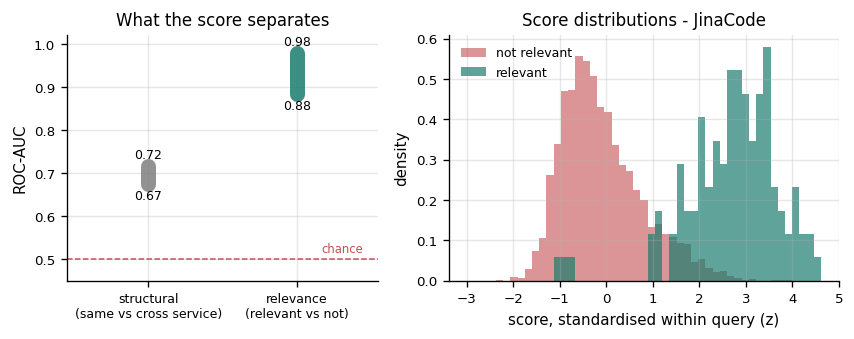

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(IEEE_WIDE, 2.9),
                         gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
labels = ["structural\n(same vs cross service)", "relevance\n(relevant vs not)"]
sv = [CLAIMS["geo.struct_auc_lo"]["value"], CLAIMS["geo.struct_auc_hi"]["value"]]
rv = [CLAIMS["geo.rel_auc_lo"]["value"],    CLAIMS["geo.rel_auc_hi"]["value"]]
for k, (lo, hi, c) in enumerate([(sv[0], sv[1], "#7F7F7F"), (rv[0], rv[1], "#1B7C6F")]):
    ax.plot([k, k], [lo, hi], lw=9, color=c, solid_capstyle="round", alpha=0.85)
    ax.text(k, hi + 0.018, f"{hi:.2f}", ha="center", fontsize=7.5)
    ax.text(k, lo - 0.035, f"{lo:.2f}", ha="center", fontsize=7.5)
ax.axhline(0.5, color="#C44E52", lw=0.9, ls="--")
ax.text(1.45, 0.515, "chance", fontsize=7, color="#C44E52", ha="right")
ax.set_xticks([0, 1]); ax.set_xticklabels(labels, fontsize=7.5)
ax.set_xlim(-0.55, 1.55); ax.set_ylim(0.45, 1.02)
ax.set_ylabel("ROC-AUC"); ax.set_title("What the score separates")

ax = axes[1]
bname = next(n for n in DENSE_ONLY if DISPLAY[n] == CLAIMS["geo.rel_auc_best_config"]["value"])
S = SCORES[bname]; Zbest = (S - S.mean(1, keepdims=True)) / S.std(1, keepdims=True)
bins = np.linspace(min(Zbest.min(), -3), Zbest.max(), 50)
ax.hist(Zbest[~Y], bins=bins, density=True, color="#C44E52", alpha=0.6, label="not relevant")
ax.hist(Zbest[Y],  bins=bins, density=True, color="#1B7C6F", alpha=0.7, label="relevant")
ax.set_xlabel("score, standardised within query (z)"); ax.set_ylabel("density")
ax.set_title(f"Score distributions - {CLAIMS['geo.rel_auc_best_config']['value']}")
ax.legend(fontsize=7.5)
fig.tight_layout(); savefig(fig, "05_relevance_separability"); plt.show()

**Figure 5.** Left: the range across models of ROC-AUC for the two different questions. Separating
**structural** proximity gives 0.67-0.72; separating **relevance** gives 0.88-0.98. The two bars are
not two estimates of one quantity; they answer two different questions, and the distance between
them is what matters here. Right: within-query standardised scores for JinaCode, relevant against
irrelevant pairs (111 of 3,478 pairs are relevant, 3.2%). The distributions are well separated but
they still overlap, and the overlap is where a fixed cut-off has to make its mistakes.

### Sub-question 3: What the Data Shows

**Structural proximity and relevance are separated very differently by the same scores.** Separating
structural proximity by score gives ROC-AUC 0.67 to 0.72, only modestly above chance. Separating **relevance**
with the same models, over 3,478 labelled query-fragment pairs, gives **0.88 to 0.98**, and even the
weakest configuration on this criterion (0.884, the paraphrase control) separates relevance better
than the best model separated structure. On this benchmark a similarity score is therefore a strong
relevance signal, and structural proximity, which is what a filter does *not* have to decide, is the
question on which it looks weak.

**What stays true is narrower and worth keeping.** The distributions still overlap (0.14 to 0.43 of
their density, at 60 bins), so a threshold trades precision against recall instead of separating
cleanly, and it has to be set on the within-query standardised scores defined in [Section 9](#sec9).
A filter calibrated on one model's raw scale does not transfer to another model. That is a statement
about calibration, not about the score being uninformative.

**Why this section cannot explain the ranking in [Section 7](#sec7).** Fragment-to-fragment geometry
describes the corpus, while retrieval ranks fragments against a query, and for the Gemini
configurations that happens in a different embedding space per `task_type`. High similarity between
distant parts of the corpus does not imply difficult retrieval, and nothing here is offered as the cause of any
model's performance.

<a id="sec10"></a>
## 10. Sensitivity: Which Conclusions Depend on Which Choices?

Three choices in this study were reasonable but not forced, and each one could be driving a result:
the corpus is a chosen subset, the fusion constant comes from a paper about much larger collections,
and the chunks are mostly class-level. Each choice is varied here and the conclusions are checked
against the change. A sensitivity check is only worth running if it can fail, so each subsection
states the shape a failure would take before reporting what happened.

<a id="sec10-1"></a>
### 10.1 The Full 146-Fragment Corpus

The retrieval corpus holds 94 of the repository's 146 Java fragments ([2.3](#sec2-3)), chosen on
purpose. The excluded fragments are all legitimate retrieval candidates, so adding them back
cannot help any configuration, only distract it. All annotated relevant fragments are already inside
the 146, so the relevance sets stay the same and the comparison is exact: the only thing that grows is
the number of ways to be wrong.

**A failure here would look like** a reordering of the leading configurations, or the loss of the
configuration effect found in [Section 8](#sec8). Absolute scores are *expected* to fall for
everything, which is the point of adding distractors rather than a failure.

In [33]:
# ---- rebuild the full pipeline on all 146 Java fragments ---------------------
orig2java = {o: j for j, o in enumerate(JAVA_IDX)}
GT146 = [[orig2java[o] for o in q["gt_orig"]] for q in QUERIES]
assert [len(a) for a in GT146] == [len(g) for g in GT], "relevance sets must be preserved"

# E146, the embeddings of all 146 fragments, was loaded in 9.1
bm25_146 = BM25Okapi([code_tokenize(t) for t in JAVA_TEXTS])
S146 = {n: cosine_similarity(PRECOMPUTED[n]["queries"], E146[n]) for n in DENSE_CONFIGS}
S146["bm25"] = np.vstack([bm25_146.get_scores(code_tokenize(q)) for q in QUERY_TEXTS])
for h, cfg in HYBRID_CONFIGS.items():
    d = S146[cfg["dense"]]
    S146[h] = (rrf_fuse([d, S146["bm25"]], k=cfg["k"]) if cfg["method"] == "rrf"
               else wsum_fuse(d, S146["bm25"], cfg["alpha"]))

PQ146 = {n: per_query_metrics(S146[n], GT146) for n in CONFIGS}

sens = pd.DataFrame({
    "nDCG@5 (94)":  [PQ[n][PRIMARY].mean() for n in CONFIGS],
    "nDCG@5 (146)": [PQ146[n][PRIMARY].mean() for n in CONFIGS],
    "R-Prec (94)":  [PQ[n]["R-Prec"].mean() for n in CONFIGS],
    "R-Prec (146)": [PQ146[n]["R-Prec"].mean() for n in CONFIGS],
}, index=[DISPLAY[n] for n in CONFIGS]).round(4)
sens["delta nDCG@5"] = (sens["nDCG@5 (146)"] - sens["nDCG@5 (94)"]).round(4)
sens["rank (94)"]  = sens["nDCG@5 (94)"].rank(ascending=False).astype(int)
sens["rank (146)"] = sens["nDCG@5 (146)"].rank(ascending=False).astype(int)
display(sens)

rho = stats.spearmanr(sens["nDCG@5 (94)"], sens["nDCG@5 (146)"]).statistic
chi2_146, p_146 = stats.friedmanchisquare(*[PQ146[n][PRIMARY].values for n in CONFIGS])
top94, top146 = sens["nDCG@5 (94)"].idxmax(), sens["nDCG@5 (146)"].idxmax()

claim("sens.n_corpus_146", len(JAVA_TEXTS))
claim("sens.n_added", len(JAVA_TEXTS) - len(CORPUS_TEXTS))
claim("sens.mean_drop", float(-sens["delta nDCG@5"].mean()))
claim("sens.max_drop", float(-sens["delta nDCG@5"].min()))
claim("sens.rank_rho", float(rho))
claim("sens.top_94", top94); claim("sens.top_146", top146)
claim("sens.top_preserved", bool(top94 == top146))
claim("sens.friedman_p_146", float(p_146))
claim("sens.n_rank_changes", int((sens["rank (94)"] != sens["rank (146)"]).sum()))
claim("sens.best_146_score", float(sens["nDCG@5 (146)"].max()))

,nDCG@5 (94),nDCG@5 (146),R-Prec (94),R-Prec (146),delta nDCG@5,rank (94),rank (146)
MiniLM-L6,0.6700,0.6444,0.6113,0.5707,-0.0256,9,9
MPNet,0.7464,0.7076,0.6550,0.6234,-0.0388,8,7
Paraphrase-L3,0.5453,0.4754,0.4669,0.4051,-0.0699,12,12
UniXcoder,0.5526,0.4784,0.4167,0.3707,-0.0742,11,11
JinaCode,0.8787,0.8579,0.8095,0.7734,-0.0208,1,1
Gemini-RETR,0.8258,0.7895,0.7140,0.6838,-0.0363,2,2
Gemini-CODE,0.8228,0.7881,0.7320,0.7018,-0.0347,3,3
BM25,0.6467,0.6346,0.5288,0.5144,-0.0121,10,10
RRF(Gem+BM25),0.8159,0.7685,0.6946,0.6149,-0.0474,5,4
WSum(Gem+BM25),0.7651,0.7421,0.6608,0.6306,-0.0230,6,6


0.8579

Adding the 52 withheld fragments costs every configuration something, on average 0.041 nDCG@5 and at
worst 0.074. The chosen corpus does make retrieval easier, and the absolute numbers in this study
are optimistic. **The conclusions, however, hold.** The ordering of configurations is essentially
preserved (Spearman ρ = 0.986, 4 of 12 configurations change rank), the leading configuration is
unchanged (JinaCode at 94, JinaCode at 146, scoring 0.858), and the configuration effect remains
decisive (Friedman p = 1.17e-10). What the corpus choice inflates is the score level, not the
comparison.

<a id="sec10-2"></a>
### 10.2 The Fusion Constant `k`

`k = 60` comes from the literature rather than from this benchmark ([3.3](#sec3-3)). Its role in RRF
is to damp the contribution of the top ranks: a large `k` flattens the difference between rank 1 and
rank 10, which on a 94-fragment corpus may be most of the available signal. [Section 7](#sec7) found
that fusion does not improve on the best dense configuration, and that finding would be worth little
if it depended on an unsuitable `k`.

**A failure here would look like** a value of `k` at which fusion overtakes the best dense
configuration, which would mean the conclusion was about `k` rather than about fusion. Finding such a
`k` and adopting it would be tuning on the evaluation set, so the sweep is reported as a robustness
check and `k = 60` stays the reported configuration either way.

fusion,RRF(Gem+BM25),RRF(Jina+BM25),RRF(MPNet+BM25)
k,,,
1,0.8144,0.8173,0.7558
5,0.8250,0.8281,0.7674
10,0.8209,0.8268,0.7749
20,0.8231,0.8275,0.7536
40,0.8155,0.8295,0.7497
60,0.8159,0.8213,0.7477
100,0.8104,0.8210,0.7436
200,0.7981,0.8102,0.7536


  fig: 06_rrf_k_sweep


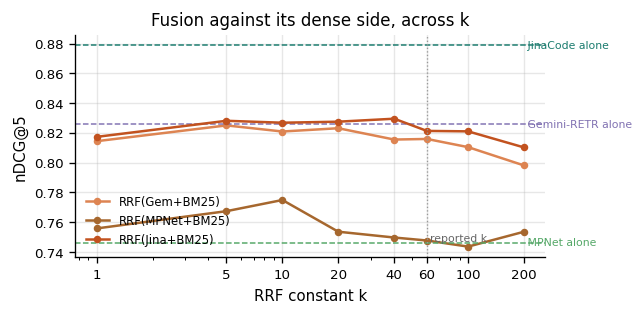

-0.04919241025446497

In [34]:
K_GRID = [1, 5, 10, 20, 40, 60, 100, 200]
best_dense_score = PQ[BEST_KEY][PRIMARY].mean() if FAMILY[BEST_KEY] == "dense" else None
sweep_rows = []
for hname, hcfg in HYBRID_CONFIGS.items():
    if hcfg["method"] != "rrf": continue
    d = SCORES[hcfg["dense"]]
    for k in K_GRID:
        s = rrf_fuse([d, BM25_SCORES], k=k)
        sweep_rows.append({"fusion": DISPLAY[hname], "dense side": DISPLAY[hcfg["dense"]], "k": k,
                           "nDCG@5": round(float(np.mean([ndcg_at_k(ranking(s[i]), GT[i], 5)
                                                          for i in range(len(GT))])), 4)})
sweep = pd.DataFrame(sweep_rows)
display(sweep.pivot(index="k", columns="fusion", values="nDCG@5"))

fig, ax = plt.subplots(figsize=(IEEE_COL * 1.55, 2.7))
for hname, hcfg in HYBRID_CONFIGS.items():
    if hcfg["method"] != "rrf": continue
    sub = sweep[sweep.fusion == DISPLAY[hname]]
    ax.plot(sub.k, sub["nDCG@5"], marker="o", ms=3.5, color=color(hname), label=DISPLAY[hname])
    ds = PQ[hcfg["dense"]][PRIMARY].mean()
    ax.axhline(ds, color=color(hcfg["dense"]), ls="--", lw=0.9)
    ax.text(K_GRID[-1], ds, f" {DISPLAY[hcfg['dense']]} alone", fontsize=6.5,
            color=color(hcfg["dense"]), va="center")
ax.axvline(60, color="#999999", lw=0.8, ls=":")
ax.text(62, ax.get_ylim()[0] + 0.01, "reported k", fontsize=6.5, color="#666666")
ax.set_xscale("log"); ax.set_xticks(K_GRID); ax.set_xticklabels(K_GRID)
ax.set_xlabel("RRF constant k"); ax.set_ylabel("nDCG@5")
ax.set_title("Fusion against its dense side, across k")
ax.legend(fontsize=7, loc="lower left")
fig.tight_layout(); savefig(fig, "06_rrf_k_sweep"); plt.show()

beats = []
for hname, hcfg in HYBRID_CONFIGS.items():
    if hcfg["method"] != "rrf": continue
    ds = PQ[hcfg["dense"]][PRIMARY].mean()
    sub = sweep[sweep.fusion == DISPLAY[hname]]
    if (sub["nDCG@5"] > ds).any():
        b = sub.loc[sub["nDCG@5"].idxmax()]
        beats.append((DISPLAY[hname], int(b.k), float(b["nDCG@5"]), float(ds)))
claim("sens.k_grid", str(K_GRID))
claim("sens.k_best_overall", int(sweep.loc[sweep["nDCG@5"].idxmax(), "k"]))
claim("sens.k_sweep_span", float(sweep.groupby("fusion")["nDCG@5"].apply(lambda s: s.max()-s.min()).max()))
claim("sens.n_fusions_beating_dense", len(beats))
claim("sens.fusion_best_vs_code",
      float(sweep[sweep.fusion == DISPLAY['hybrid-rrf-code']]["nDCG@5"].max() - PQ["jina-code-0.5b"][PRIMARY].mean()))

**Figure 6.** nDCG@5 of each RRF fusion as `k` varies over [1, 5, 10, 20, 40, 60, 100, 200], with
each fusion's dense side shown as a dashed reference line. Across the whole grid the fusion never
overtakes `JinaCode` alone: the best value any fusion reaches is -0.049 nDCG@5 relative to the
leading dense configuration. The largest change `k` produces within one fusion is 0.031, so the
choice of `k` matters far less than the choice of what to fuse. The conclusion in [Section 7](#sec7)
does not depend on `k = 60`.

<a id="sec10-3"></a>
### 10.3 Chunk Granularity

The chunking strategy produced mostly class-level fragments ([2.2](#sec2-2)). Splitting controllers
and services into methods is often expected to break their semantic context, but this design cannot
test that expectation: doing so would mean re-chunking the repository at method level and annotating
it again, which is outside the scope of this study. What the existing data do allow is a comparison of
how the two granularities already present in the corpus behave as retrieval targets.

This is an observational comparison rather than an experiment. Class-level and method-level fragments
are different code, they are targeted by different queries, and there are few method-level fragments.
It can show whether the two granularities are retrieved with comparable success, but it cannot
attribute a difference to granularity, and it is read with that limit in mind.

In [35]:
gran = pd.DataFrame({
    "pos": range(len(CORPUS_CHUNKS)),
    "granularity": [c["chunk_type"] for c in CORPUS_CHUNKS],
    "is_relevant_somewhere": [i in set().union(*[set(g) for g in GT]) for i in range(len(CORPUS_CHUNKS))],
})
gran_counts = gran.groupby("granularity").agg(fragments=("pos", "size"),
                                              ever_relevant=("is_relevant_somewhere", "sum"))
display(gran_counts)

# for each relevant fragment, the best rank it achieved under the leading configuration
S = SCORES[BEST_KEY]
rank_of = {}
for i, rel in enumerate(GT):
    order = ranking(S[i])
    pos_of = {d: r for r, d in enumerate(order, 1)}
    for d in rel:
        rank_of.setdefault(d, []).append(pos_of[d])
rank_rows = [{"granularity": CORPUS_CHUNKS[d]["chunk_type"], "fragment": d,
              "best rank achieved": min(rs), "times relevant": len(rs)}
             for d, rs in rank_of.items()]
rank_df = pd.DataFrame(rank_rows)
gsum = (rank_df.groupby("granularity")
        .agg(relevant_fragments=("fragment", "size"),
             median_best_rank=("best rank achieved", "median"),
             share_reaching_top5=("best rank achieved", lambda s: round(float((s <= 5).mean()), 3)))
        .sort_values("relevant_fragments", ascending=False))
display(gsum)

_cls = gsum.loc["class"] if "class" in gsum.index else None
_mth = gsum.loc["method"] if "method" in gsum.index else None
claim("gran.config", DISPLAY[BEST_KEY])
if _cls is not None:
    claim("gran.n_class", int(_cls.relevant_fragments)); claim("gran.top5_class", float(_cls.share_reaching_top5))
    claim("gran.medrank_class", float(_cls.median_best_rank))
if _mth is not None:
    claim("gran.n_method", int(_mth.relevant_fragments)); claim("gran.top5_method", float(_mth.share_reaching_top5))
    claim("gran.medrank_method", float(_mth.median_best_rank))

,fragments,ever_relevant
granularity,,
class,74,56
interface,4,4
method,16,16


,relevant_fragments,median_best_rank,share_reaching_top5
granularity,,,
class,56,2.0,0.911
method,16,1.0,1.000
interface,4,1.0,1.000


Under JinaCode, the relevant class-level fragments (56 of them) reach the top 5 in 91% of cases with
a median best rank of 2; the method-level ones (16) reach it in 100% of cases, median rank 1. With
only 16 method-level fragments this describes 16 data points rather than estimating a granularity
effect, and it supports no claim in either direction. What it does show is that method-level
fragments are **not** systematically missed, which is what the expectation about broken semantic
context would have predicted.

<a id="sec11"></a>
## 11. Limitations

Each limitation below says what it prevents this study from concluding, and where a limitation was
measured rather than only declared, the section that measured it is named.

**Scale and scope.** One demo repository, one language and framework stack, 37 queries, 94 fragments
in the main corpus. `internet-banking-concept-microservices` is a concept project rather than a
production system, and its size, consistent naming and lack of legacy code make it more tractable
than an enterprise codebase. Nothing here describes enterprise software. *Prevents:* any claim of
generality across repositories, languages or scales. Every result is a result about this repository.

**Corpus chosen on purpose.** The 94 fragments were chosen, not sampled ([2.3](#sec2-3)).
*Measured* in [10.1](#sec10-1): scores fall on the full 146-fragment corpus, but the ordering of
configurations holds. *Prevents:* reading the absolute score levels as estimates of real-world
performance. It does not invalidate the comparisons.

**Query-corpus circularity (chunks-first).** The queries were written after the corpus was fixed, so
each one has an answer inside it and its vocabulary may reuse that of the fragment it was written
from. No query is unanswerable, which is the common case in production. How much vocabulary
the queries share with their targets was not measured. *Prevents:* reading these
scores as retrieval accuracy in deployment. They are an upper bound under favourable conditions.

**Single annotator.** Relevance was assigned by one annotator with knowledge of the repository. No
second annotator labelled any subset, so **no agreement statistic is reported and none is implied**.
*Prevents:* telling genuine ranking failures apart from annotation disagreements, since a fragment
ranked first and labelled irrelevant may reflect a labelling judgement rather than an error.

**Statistical power, especially per category.** With 37 queries the paired tests are weak, and
splitting by category leaves 9 to 10 queries per group, where ties push the attainable *p* floor above
0.05 in several comparisons. [Section 8](#sec8) prints that floor next to each *p* for this reason.
*Prevents:* reading any non-significant per-category result as evidence of equivalence. It also means
that the two leading configurations in [Section 7](#sec7) could not have been separated even if they
do differ by the observed margin.

**Input-length confound, measured but not removed.** Three models truncate part of the corpus
([Section 6](#sec6)). The cost of the tightest budget was measured and is small compared with the
effects it might have explained, but it was measured on *one* model, and a narrow-window model might
degrade differently. *Prevents:* attributing the whole deficit of the narrow-window models to their
training objective with certainty, although that is the explanation the data support.

**Granularity is described, not manipulated.** [10.3](#sec10-3) compares granularities that already
exist in the corpus instead of re-chunking the repository, so it cannot isolate a granularity effect.
*Prevents:* any claim that class-level chunking is better or worse than method-level chunking. The
data give no support to the expectation that method-level splitting breaks semantic context: in this
corpus the method-level fragments are retrieved at least as reliably as the class-level ones.

**Untuned baselines, by design.** BM25 uses default parameters, RRF uses the `k` from the literature
and the weighted sum uses α = 0.5, for the reason given in [3.3](#sec3-3). *Measured* in
[10.2](#sec10-2) for `k`. *Prevents:* claiming that
these are the best achievable results for lexical or hybrid retrieval, since a tuned BM25 could do
better.

**The generation stage is out of scope.** Only retrieval is evaluated, for the reason given under
"Context" in the introduction: retrieval quality strongly conditions what a generation stage can
ground an answer on without fixing it. *Prevents:* any inference from these metrics to end-to-end answer quality, comprehension time or
developer productivity, all of which would need a user study.

**Deployment characteristics were not measured.** [Section 12](#sec12) notes which configurations run
locally and which need an API call, because that follows from what was tested. No latency, throughput,
index size or cost was recorded. *Prevents:* any claim about production feasibility.

<a id="sec12"></a>
## 12. Answering the Research Question

The question posed in the introduction was:

> **Which retrieval strategy, dense, lexical or hybrid, retrieves relevant code fragments best in a
> Java microservices repository, and what determines its performance?**

Every value cited below is registered in `results/claims.json`. Each part names the section that produced it and states what it does **not** establish.

### The Answer

**Dense retrieval, and specifically a code-specialised dense retriever.** On this benchmark JinaCode
leads every reported metric (7 of 7), with nDCG@5 0.879 [95% CI 0.819, 0.933], and it keeps that
position when the corpus grows to all 146 Java fragments (JinaCode, 0.858). Lexical retrieval on its
own is not competitive (+0.179 nDCG@5 against the managed API model), and **fusion does not help**:
over every value of `k` tested it never overtakes the best dense configuration (-0.049 at best,
[10.2](#sec10-2)).

*What this does not establish:* that JinaCode is better than Gemini-RETR. The paired difference is
+0.053 with p = 0.246 and overlapping intervals, so **no difference was detected between the top
two**, which at N = 37 describes the power of this benchmark rather than the models.

### What Determines Performance, and What Became of the Hypotheses

Each determinant corresponds to one of the hypotheses declared in the introduction, so each is
stated together with the verdict on its hypothesis and a pointer to the section holding the
evidence.

**1. The retrieval objective, not the training domain. (H1 fails in its mechanism.)** The two
effects that survive Holm correction in [Section 7](#sec7) are both mismatches between objective and
task: the code *retriever* beats the code *encoder* by +0.326 nDCG@5 (Holm p = 0.0003), and the
retrieval-trained general model beats the paraphrase-trained one by +0.201 (Holm p = 0.0236). H1
predicted that pre-training on code would decide the ranking, and a code-specific configuration does
lead the benchmark, so the prediction holds on its surface but not in its mechanism:
`unixcoder-base` is pre-trained on code, sees every fragment in full, and still lands near the
paraphrase control, while a code-specific *task type* is worth only +0.003 (p = 0.722). Input budget
was ruled out as the cause in [Section 6](#sec6), where the worst case costs 0.019 nDCG@5. The
objective explanation is an interpretation of these results rather than something this design
isolated, so it stands as a hypothesis for a different corpus rather than as a finding of this one.

**2. Query type, less than the configuration, and the two interact. (H2 is not supported.)** In the
mixed-effects model of [Section 8](#sec8), configuration is significant given category (p = 6.3e-15)
while category given configuration is much weaker (p = 0.033), and under permutation the category
effect does not reach significance (p = 0.058). The interaction is real (p = 0.0076) and the winner
changes by category: JinaCode in T1 - Location, Gemini-RETR in T2 - Behavior, JinaCode in T3 -
Cross-cutting, Gemini-RETR in T4 - Tests. Neither main effect therefore describes the data, so the
question as H2 poses it has no answer in this benchmark. Its mechanism fails on its own terms as
well: lexical matching is not competitive on T1, where the query names its target (0.196 nDCG@5
behind the leading dense configuration), and the hardest category is T2 - Behavior rather than the
cross-cutting one. Category remains entangled with relevance-set size by construction, although the
effect survives adjustment for it (p = 0.049).

*What this does not establish:* that retrieval quality depends **more** on query intent than on
model choice. Over the general-purpose models alone the omnibus test does not reject (p = 0.154,
spread 0.156), which is how that reading can arise; adding a purpose-built code retriever and a code
encoder widens the spread to 0.326 and reverses the comparison.

**3. A similarity score is a usable relevance signal, once standardised. (H3 survives in a weaker
form.)** Over 3,478 labelled query-fragment pairs, ROC-AUC on **relevance** is 0.88 to 0.98
([9.2](#sec9-2)); the much lower 0.67 to 0.72 measures how well similarity predicts **structural**
proximity, which is not what a confidence filter decides. H3 asked for a margin stable enough to
threshold. The margin is real but not stable in raw units: the two distributions overlap (0.14 to
0.43 of their density) and the scores have to be standardised within each query, so a fixed cut-off
on raw similarity transfers neither across models nor across queries. A confidence filter is
feasible on standardised scores, and it trades precision against recall rather than separating
cleanly.

### Practical Consequence

For a repository of this kind, the configuration that performed best also **runs locally**: JinaCode
is open-weights, so in this study a privacy-restricted deployment is not a compromise on retrieval
quality but the leading option. A managed API was not needed to reach the top of this benchmark, and
adding a lexical component to the best dense retriever did not improve it. On the evidence of the
interaction, routing by query type would be expected to help, while switching between the top-ranked
models would not.

### Status of These Findings

Exploratory. One demo repository, 37 queries, a single annotator, a corpus chosen on purpose, and
queries written after the corpus was fixed ([Section 11](#sec11)). Two of the three answers above depend on choices made inside the study, namely how
wide the model set is and whether the embedding-space analysis is pointed at relevance or at
structure, which is the strongest reason to treat all of them as provisional.

<a id="sec13"></a>
## 13. Export

Three groups of artifacts are written, for different readers:

* **`results/claims.json`**, every value registered through `claim()`, keyed by a stable id. This is
  the record the manuscript's figures are taken from and can be checked against, so a value used in
  the paper can always be traced back to the cell that computed it.
* **`results/metrics.json`**, **`results/provenance.json`** and the per-query CSVs, that is the full
  numeric record, the pinned environment, and the raw per-query scores for independent re-analysis.
* **`docs/benchmark.json`** and **`docs/queries.csv`**, the benchmark itself: all 37 queries with
  their category and relevance labels, plus the list of selected fragments. They are published so that
  the benchmark can be reused or disputed without deriving it again.

In [36]:
# ---- benchmark: queries, labels, selected fragments -------------------------
benchmark = {
    "study_repo": STUDY_REPO,
    "taxonomy": DS["taxonomy"],
    "corpus": [{"pos": i, "orig_chunk_index": CORPUS_ORIG[i],
                "component": cmeta(c, "class_name") or cmeta(c, "method_name") or "",
                "chunk_type": c["chunk_type"],
                "component_type": cmeta(c, "spring_type") or c["chunk_type"],
                "service": chunk_service(c), "path": chunk_path(c),
                "is_distractor": i in set(distractors)}
               for i, c in enumerate(CORPUS_CHUNKS)],
    "queries": [{"id": q["id"], "category": q["category"], "text": q["text"],
                 "relevant_positions": q["gt_pos"], "relevant_components": q["gt_names"],
                 "n_relevant": len(q["gt_pos"])}
                for q in QUERIES],
}
DOCS_DIR = NB_DIR / "docs"; DOCS_DIR.mkdir(exist_ok=True)
(DOCS_DIR / "benchmark.json").write_text(json.dumps(benchmark, indent=2, ensure_ascii=False))
queries_df.to_csv(DOCS_DIR / "queries.csv", index=False)

# ---- the registry the paper cites -------------------------------------------
(RESULTS_DIR / "claims.json").write_text(json.dumps(
    {"generated_at": PROVENANCE["generated_at"],
     "claims": {k: v for k, v in sorted(CLAIMS.items())}}, indent=2, ensure_ascii=False))
(RESULTS_DIR / "provenance.json").write_text(json.dumps(PROVENANCE, indent=2, ensure_ascii=False))

# ---- full numeric record -----------------------------------------------------
export = {
    "meta": {
        "n_corpus": len(CORPUS_TEXTS), "n_full_corpus": len(all_chunks),
        "n_java_corpus": len(JAVA), "n_queries": len(QUERIES),
        "n_configurations": len(CONFIGS),
        "queries_by_category": {catlabel(c): CLAIMS[f"bench.n_queries.{c}"]["value"] for c in CATS},
        "mean_relevant_by_category": {catlabel(c): CLAIMS[f"bench.mean_relevant.{c}"]["value"] for c in CATS},
        "ceilings": {"mean_P@5": CLAIMS["bench.mean_P5_ceiling"]["value"],
                     "mean_R@5": CLAIMS["bench.mean_R5_ceiling"]["value"],
                     "mean_R@10": CLAIMS["bench.mean_R10_ceiling"]["value"],
                     "queries_with_more_than_5_relevant": CLAIMS["bench.n_queries_gt5"]["value"]},
        "n_distractors": len(distractors),
        "annotators": 1, "cohen_kappa": None,        # not measured - see section 11
        "primary_metric": PRIMARY,
        "hybrids": HYBRID_CONFIGS,
    },
    "summary": summary.reset_index().rename(columns={"index": "config"}).to_dict("records"),
    "bootstrap_ci": ci_rows,
    "omnibus": omni_df.drop(columns="members").to_dict("records"),
    "pairwise_wilcoxon_holm": wx_df.to_dict("records"),
    "input_budget": {"exposure": trunc_df.reset_index().to_dict("records"),
                     "cost_by_budget": budget_df.to_dict("records")},
    "category_by_config_nDCG5": cat_tab.reset_index().rename(columns={"index": "config"}).to_dict("records"),
    "mixed_effects_lrt": lr_df.to_dict("records"),
    "permutation_tests": perm_df.to_dict("records"),
    "category_wilcoxon_dense_vs_bm25": cat_wx_df.to_dict("records"),
    "embedding_space": {"structural_discrimination": disc_df.to_dict("records"),
                        "relevance_separability": rel_auc_df.reset_index().to_dict("records")},
    "sensitivity": {"corpus_94_vs_146": sens.reset_index().rename(columns={"index": "config"}).to_dict("records"),
                    "rrf_k_sweep": sweep.to_dict("records"),
                    "granularity": gsum.reset_index().to_dict("records")},
}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(export, indent=2, ensure_ascii=False, default=str))

summary.to_csv(RESULTS_DIR / "summary.csv")
cat_tab.to_csv(RESULTS_DIR / "category_by_config.csv")
ci_df.to_csv(RESULTS_DIR / "bootstrap_ci.csv", index=False)
wx_df.to_csv(RESULTS_DIR / "pairwise_wilcoxon.csv", index=False)
trunc_df.to_csv(RESULTS_DIR / "input_budget.csv")
rel_auc_df.to_csv(RESULTS_DIR / "relevance_separability.csv")
sens.to_csv(RESULTS_DIR / "sensitivity_corpus.csv")
sweep.to_csv(RESULTS_DIR / "sensitivity_rrf_k.csv", index=False)
for n in CONFIGS:
    PQ[n].to_csv(RESULTS_DIR / f"per_query_{DISPLAY[n].replace('/', '-')}.csv")

print(f"{len(CLAIMS)} registered values")
print("\nresults/"); [print("  ", f.name) for f in sorted(RESULTS_DIR.iterdir()) if f.is_file()]
print("docs/");      [print("  ", f.name) for f in sorted(DOCS_DIR.iterdir()) if f.is_file()]

298 registered values

results/
   01_chunk_granularity.pdf
   01_chunk_granularity.png
   02_retrieval_metrics.pdf
   02_retrieval_metrics.png
   03_category_by_config.pdf
   03_category_by_config.png
   04_interaction.pdf
   04_interaction.png
   05_relevance_separability.pdf
   05_relevance_separability.png
   06_rrf_k_sweep.pdf
   06_rrf_k_sweep.png
   bootstrap_ci.csv
   category_by_config.csv
   claims.json
   input_budget.csv
   metrics.json
   pairwise_wilcoxon.csv
   per_query_BM25.csv
   per_query_Gemini-CODE.csv
   per_query_Gemini-RETR.csv
   per_query_JinaCode.csv
   per_query_MPNet.csv
   per_query_MiniLM-L6.csv
   per_query_Paraphrase-L3.csv
   per_query_RRF(Gem+BM25).csv
   per_query_RRF(Jina+BM25).csv
   per_query_RRF(MPNet+BM25).csv
   per_query_UniXcoder.csv
   per_query_WSum(Gem+BM25).csv
   provenance.json
   relevance_separability.csv
   sensitivity_corpus.csv
   sensitivity_rrf_k.csv
   summary.csv
docs/
   benchmark.json
   queries.csv
   study_repo_tree.txt


[None, None, None]